# Data importing and preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.naive_bayes import GaussianNB, BernoulliNB, ComplementNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")

In [2]:
#Read data
df = pd.read_csv("Fifa.csv")

# Clean column names
df.columns = df.columns.str.strip()

In [3]:
print("Dataset Shape:", df.shape)
df.info()
df.describe()

Dataset Shape: (19667, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19667 entries, 0 to 19666
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               19667 non-null  object 
 1   Country            19667 non-null  object 
 2   Position           19667 non-null  object 
 3   Age                19667 non-null  int64  
 4   Overall_Rating     19667 non-null  int64  
 5   Future Potential   19667 non-null  int64  
 6   Team               19667 non-null  object 
 7   Value Per M$       19667 non-null  float64
 8   Total_Stats Score  19667 non-null  int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 1.4+ MB


,Age,Overall_Rating,Future Potential,Value Per M$,Total_Stats Score
count,19667.000000,19667.000000,19667.000000,19667.000000,19667.000000
mean,22.990034,63.225403,70.658718,2.514639,1534.513907
std,4.692410,7.812716,6.489551,7.256974,283.248088
min,15.000000,36.000000,46.000000,0.000000,416.000000
25%,19.000000,58.000000,66.000000,0.325000,1388.000000
50%,22.000000,63.000000,70.000000,0.675000,1549.000000
75%,26.000000,68.000000,75.000000,1.600000,1720.000000
max,44.000000,91.000000,95.000000,190.500000,2324.000000


In [4]:
#Are there any missing values? How many, and in which columns?#Are there any missing values? How many, and in which columns?#Are there any missing values? How many, and in which columns?#Are there any missing values? How many, and in which columns?#Are there any missing values? How many, and in which columns?
print(df.isnull().sum())

Name                 0
Country              0
Position             0
Age                  0
Overall_Rating       0
Future Potential     0
Team                 0
Value Per M$         0
Total_Stats Score    0
dtype: int64


In [5]:
#this data doesn't have any missing value

In [6]:
# What does the distribution of Value Per M$ look like?
df["Value Per M$"].skew()    # this distribution is right-skewed because result number larger than 0


np.float64(7.983215201865151)

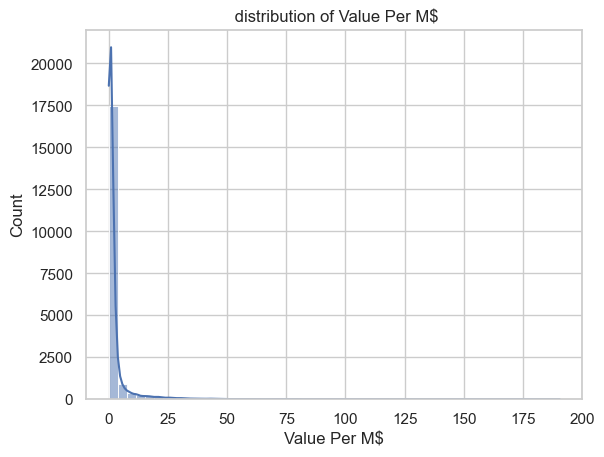

In [7]:
# visualization to the image of the distribution of Value Per M$ look like
sns.histplot(df["Value Per M$"], bins=50, kde=True)
plt.title(" distribution of Value Per M$")
plt.show()

In [8]:
# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

print("Numerical Columns:\n", num_cols)
print("\nCategorical Columns:\n", cat_cols)

Numerical Columns:
 Index(['Age', 'Overall_Rating', 'Future Potential', 'Value Per M$',
       'Total_Stats Score'],
      dtype='object')

Categorical Columns:
 Index(['Name', 'Country', 'Position', 'Team'], dtype='object')


In [9]:
#numerical feature is 'Age', 'Overall_Rating', 'Future Potential', 'Value Per M$',  'Total_Stats Score'

In [10]:
numerical_cols_for_corr = df[num_cols].drop(columns=['Value Per M$'])
correlation = numerical_cols_for_corr.corrwith(df['Value Per M$']).sort_values(ascending=False)
print(correlation)

Overall_Rating       0.560648
Future Potential     0.500964
Total_Stats Score    0.385062
Age                  0.142276
dtype: float64


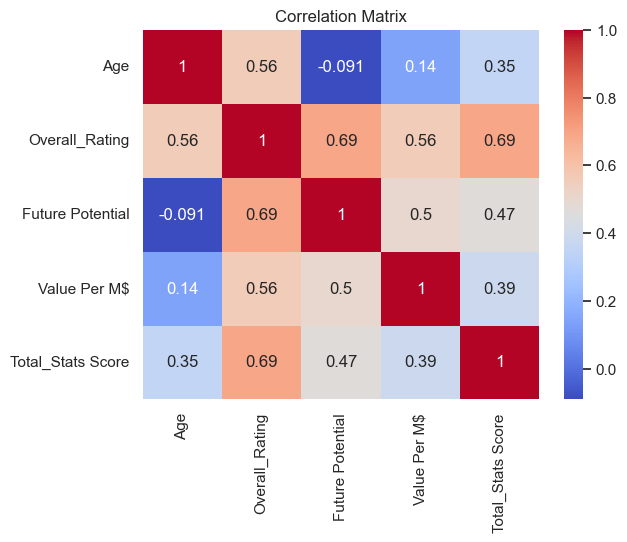

In [11]:
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

then we observe overall_rating most related and effect on value per M$

In [12]:
# What is the average Overall_Rating per Position?
average_Overall_Rating=df.groupby("Position")["Overall_Rating"].mean()
print(average_Overall_Rating)

Position
CAM    63.679709
CB     63.544448
CDM    64.234168
CF     66.042857
CM     62.511767
GK     60.987288
LB     63.276794
LM     64.172009
LW     64.345979
LWB    64.043333
RB     62.863636
RF     75.000000
RM     63.907731
RW     63.718529
RWB    64.063973
ST     63.087505
SW     75.000000
Name: Overall_Rating, dtype: float64


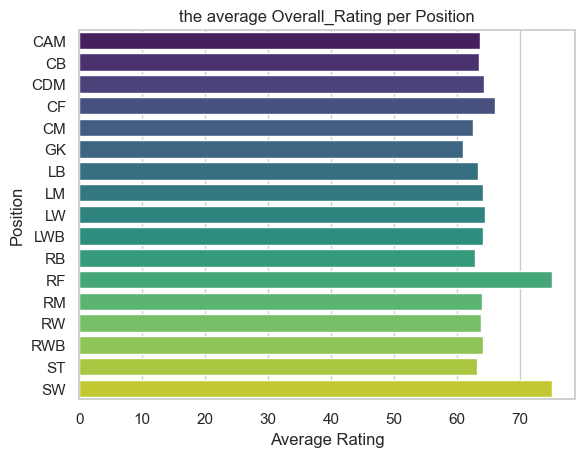

In [13]:
sns.barplot(x=average_Overall_Rating.values, y=average_Overall_Rating.index, palette='viridis')
plt.title("the average Overall_Rating per Position")
plt.xlabel('Average Rating')
plt.ylabel('Position')
plt.show()

Data PreProcessing

In [14]:
#remove name , country, team becouse not affected on result/model

features_to_use = ['Age', 'Future Potential', 'Total_Stats Score', 'Position']
x = df[features_to_use]
y_reg = df['Value Per M$']
y_clf = df['Overall_Rating']


X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    x, y_reg, y_clf, test_size=0.2, random_state=42 
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (15733, 4), Test shape: (3934, 4)


In [15]:
#make encoder on categorical column (position)
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

position_train_encoded = encoder.fit_transform(X_train[['Position']])
position_test_encoded = encoder.transform(X_test[['Position']])

position_cols = [f'Position_{cat}' for cat in encoder.categories_[0]]
position_train_df = pd.DataFrame(position_train_encoded, columns=position_cols, index=X_train.index)
position_test_df = pd.DataFrame(position_test_encoded, columns=position_cols, index=X_test.index)

print(f"Columns: {position_train_df.columns.tolist()}")

X_train_encoded = pd.concat([X_train.drop(columns=['Position']), position_train_df], axis=1)
X_test_encoded = pd.concat([X_test.drop(columns=['Position']), position_test_df], axis=1)


print(f"Shape after OneHotEncoder: {X_train_encoded.shape}")
print(f"Columns: {X_train_encoded.columns.tolist()}")

Columns: ['Position_CAM', 'Position_CB', 'Position_CDM', 'Position_CF', 'Position_CM', 'Position_GK', 'Position_LB', 'Position_LM', 'Position_LW', 'Position_LWB', 'Position_RB', 'Position_RF', 'Position_RM', 'Position_RW', 'Position_RWB', 'Position_ST', 'Position_SW']
Shape after OneHotEncoder: (15733, 20)
Columns: ['Age', 'Future Potential', 'Total_Stats Score', 'Position_CAM', 'Position_CB', 'Position_CDM', 'Position_CF', 'Position_CM', 'Position_GK', 'Position_LB', 'Position_LM', 'Position_LW', 'Position_LWB', 'Position_RB', 'Position_RF', 'Position_RM', 'Position_RW', 'Position_RWB', 'Position_ST', 'Position_SW']


In [16]:
numerical_features = ['Age', 'Future Potential', 'Total_Stats Score']   

#scalling for numerical feature
scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[numerical_features] = scaler.fit_transform(X_train_encoded[numerical_features])
X_test_scaled[numerical_features] = scaler.transform(X_test_encoded[numerical_features])


#scalling for regression
scaler_reg = StandardScaler()

y_reg_train_scaled = scaler_reg.fit_transform(y_reg_train.values.reshape(-1, 1)).ravel()
y_reg_test_scaled = scaler_reg.transform(y_reg_test.values.reshape(-1, 1)).ravel()

# no scaling for target classification because classification not need to making scaling 



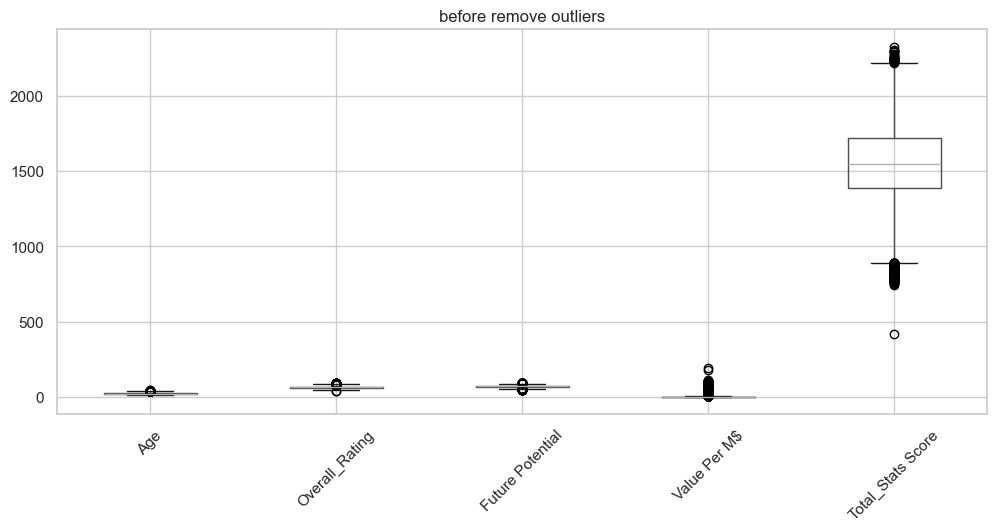

In [17]:
plt.figure(figsize=(12, 5))
df[num_cols].boxplot()
plt.xticks(rotation=45)
plt.title("before remove outliers")
plt.show()

In [18]:
outliers_count = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outliers_count[col] = len(outliers)
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

    print(f"\n{col}:")
    print(f"  - Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
    print(f"  - Lower bound: {lower_bound:.2f}, Upper bound: {upper_bound:.2f}")
    print(f"  - Number of outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")
    print(f"  - Outlier values range: {outliers[col].min():.2f} to {outliers[col].max():.2f}")


    
  


Age:
  - Q1: 19.00, Q3: 26.00, IQR: 7.00
  - Lower bound: 8.50, Upper bound: 36.50
  - Number of outliers: 169 (0.87%)
  - Outlier values range: 37.00 to 44.00

Overall_Rating:
  - Q1: 58.00, Q3: 68.00, IQR: 10.00
  - Lower bound: 43.00, Upper bound: 83.00
  - Number of outliers: 144 (0.74%)
  - Outlier values range: 36.00 to 91.00

Future Potential:
  - Q1: 66.00, Q3: 75.00, IQR: 9.00
  - Lower bound: 52.50, Upper bound: 88.50
  - Number of outliers: 74 (0.38%)
  - Outlier values range: 46.00 to 91.00

Value Per M$:
  - Q1: 0.33, Q3: 1.60, IQR: 1.28
  - Lower bound: -1.59, Upper bound: 3.51
  - Number of outliers: 2223 (13.03%)
  - Outlier values range: 3.60 to 55.50

Total_Stats Score:
  - Q1: 1372.00, Q3: 1660.00, IQR: 288.00
  - Lower bound: 940.00, Upper bound: 2092.00
  - Number of outliers: 1099 (6.89%)
  - Outlier values range: 745.00 to 2168.00


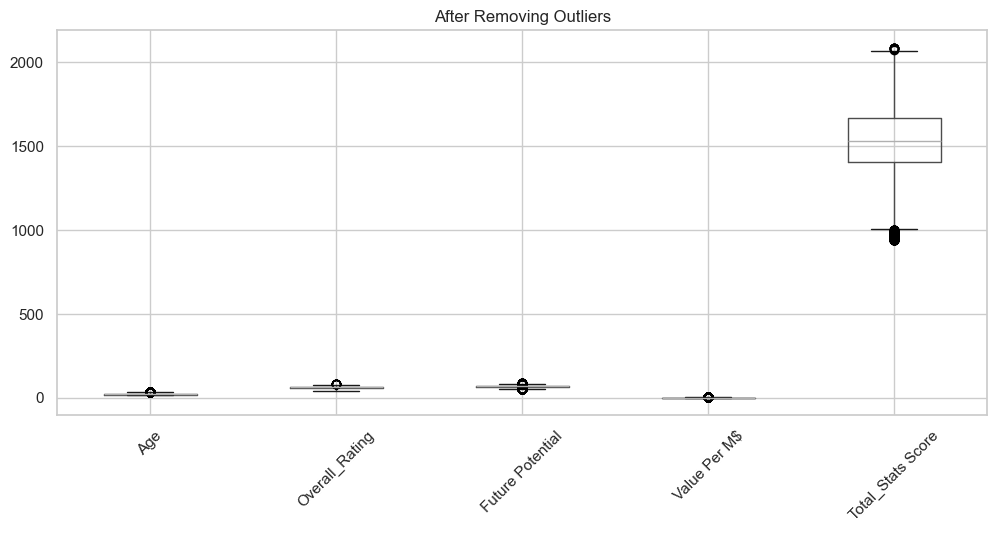

In [19]:
plt.figure(figsize=(12, 5))
df[num_cols].boxplot() 
plt.xticks(rotation=45)
plt.title("After Removing Outliers")
plt.show()

In [20]:
df.head()

,Name,Country,Position,Age,Overall_Rating,Future Potential,Team,Value Per M$,Total_Stats Score
0,Agostinho Mabululu,Angola,LW,30,68,68,Ittihad Alexandria,0.65,1660
1,Mahmoud Gennesh,Egypt,GK,35,67,67,Ittihad Alexandria,0.35,1620
2,Sobhi Suleiman,Egypt,GK,28,63,65,Ittihad Alexandria,0.20,1480
3,Mahmoud Alaa,Egypt,CB,32,68,68,Ittihad Alexandria,0.50,1695
4,Mahmoud Shabana,Egypt,CB,30,66,66,Ittihad Alexandria,0.40,1640


Create Classification Target

In [21]:
df['Overall_Rating'].describe()

count    15958.000000
mean        61.708046
std          6.078433
min         44.000000
25%         57.000000
50%         62.000000
75%         66.000000
max         83.000000
Name: Overall_Rating, dtype: float64

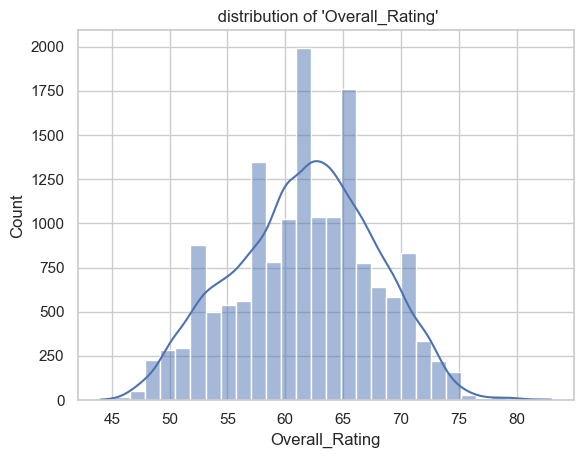

In [22]:
sns.histplot(df['Overall_Rating'], bins=30, kde=True)
plt.title(" distribution of 'Overall_Rating'")
plt.show()

In [23]:
df['Overall_Rating'].skew()

np.float64(-0.10675782884510901)

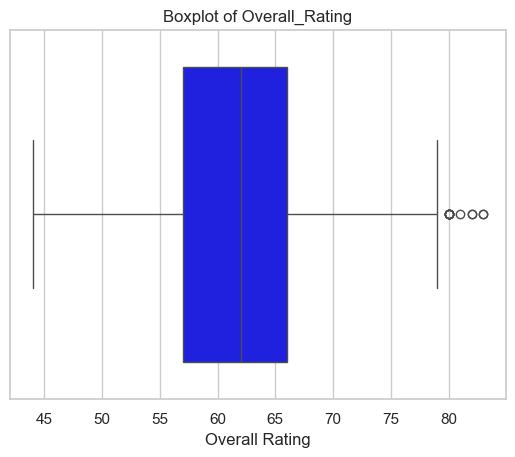

In [24]:
sns.boxplot(x=df['Overall_Rating'], color='blue')
plt.title('Boxplot of Overall_Rating')
plt.xlabel('Overall Rating')
plt.show()

In [25]:
q1 = df['Overall_Rating'].quantile(0.25)
q2 = df['Overall_Rating'].quantile(0.5)
q3 = df['Overall_Rating'].quantile(0.75)

def classify_player(r):
    if r <= q1:
        return 'Low'
    elif r <= q2:
        return 'Mid'
    elif r <= q3:
        return 'High'
    else:
        return 'Elite'

df['Overall_Rating'] = df['Overall_Rating'].apply(classify_player)
 

In [26]:
X = df[['Age', 'Future Potential', 'Total_Stats Score', 'Position']]
y_clf = df['Overall_Rating']
y_reg = df['Value Per M$']

X_train, X_test, y_clf_train, y_clf_test ,y_reg_train, y_reg_test= train_test_split(

    X,
    y_clf,
    y_reg,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

encoder = OneHotEncoder( sparse_output=False, handle_unknown='ignore')
position_train = encoder.fit_transform(X_train[['Position']])
position_test = encoder.transform( X_test[['Position']])
position_cols = [f'Position_{cat}'for cat in encoder.categories_[0]]
position_train_df = pd.DataFrame(position_train,columns=position_cols,index=X_train.index)
position_test_df = pd.DataFrame(position_test,columns=position_cols,index=X_test.index)
X_train_encoded = pd.concat([X_train.drop('Position', axis=1),position_train_df],axis=1)
X_test_encoded = pd.concat([X_test.drop('Position', axis=1),position_test_df],axis=1)


scaler = StandardScaler()
numerical_features = ['Age','Future Potential','Total_Stats Score']
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()
X_train_scaled[numerical_features] = scaler.fit_transform(X_train_encoded[numerical_features])
X_test_scaled[numerical_features] = scaler.transform(X_test_encoded[numerical_features])

scaler_reg = StandardScaler()
y_reg_train_scaled = scaler_reg.fit_transform( y_reg_train.values.reshape(-1,1)).ravel()
y_reg_test_scaled = scaler_reg.transform( y_reg_test.values.reshape(-1,1)).ravel()




In [27]:
print("Number of Players per Performance Tier:")
tier_counts = df['Overall_Rating'] .value_counts()
print(tier_counts)

Number of Players per Performance Tier:
Overall_Rating
Mid      4486
Low      4021
High     3831
Elite    3620
Name: count, dtype: int64


In [28]:
print("Percentage Distribution:")
tier_percentages = df['Overall_Rating'] .value_counts(normalize=True) * 100
for tier, pct in tier_percentages.items():
    print(f"{tier}: {pct:.2f}%")

Percentage Distribution:
Mid: 28.11%
Low: 25.20%
High: 24.01%
Elite: 22.68%


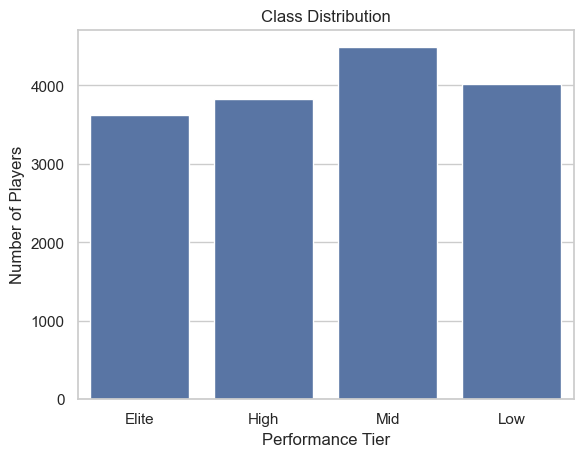

In [29]:
sns.countplot(x='Overall_Rating', data=df)
plt.title("Class Distribution")
plt.xlabel('Performance Tier')
plt.ylabel('Number of Players')

plt.show()

In [30]:
min_count = tier_counts.min()
max_count = tier_counts.max()
ratio = max_count / min_count

print(f"Smallest class size: {min_count}")
print(f"Largest class size: {max_count}")
print(f"Imbalance ratio (max/min): {ratio:.2f}")

Smallest class size: 3620
Largest class size: 4486
Imbalance ratio (max/min): 1.24


In [31]:
if ratio < 1.5:
    print("Conclusion: The dataset is BALANCED")
elif ratio < 3:
    print("Conclusion: The dataset is MODERATELY IMBALANCED")
else:
    print("Conclusion: The dataset is HIGHLY IMBALANCED")

Conclusion: The dataset is BALANCED


 Model 1: Polynomial Regression

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [33]:
degrees = [1, 2, 3, 4]
results = []

for d in degrees:
    # Expand features for the current degree
    poly = PolynomialFeatures(degree=d)
    X_poly_train = poly.fit_transform(X_train_scaled)
    X_poly_test = poly.transform(X_test_scaled)
    
    # Train model
    model = LinearRegression()
    model.fit(X_poly_train, y_reg_train_scaled)

    train_pred = model.predict(X_poly_train)
    test_pred = model.predict(X_poly_test)
    
    # Evaluate
    train_r2 = r2_score(y_reg_train_scaled, train_pred)
    test_r2 = r2_score(y_reg_test_scaled, test_pred)
    results.append([d, train_r2, test_r2])

results_df = pd.DataFrame(results, columns=['Degree', 'Train R2', 'Test R2'])
print(results_df)


   Degree  Train R2   Test R2
0       1  0.595264  0.582939
1       2  0.764016  0.746229
2       3  0.805507  0.761070
3       4  0.825255  0.766660


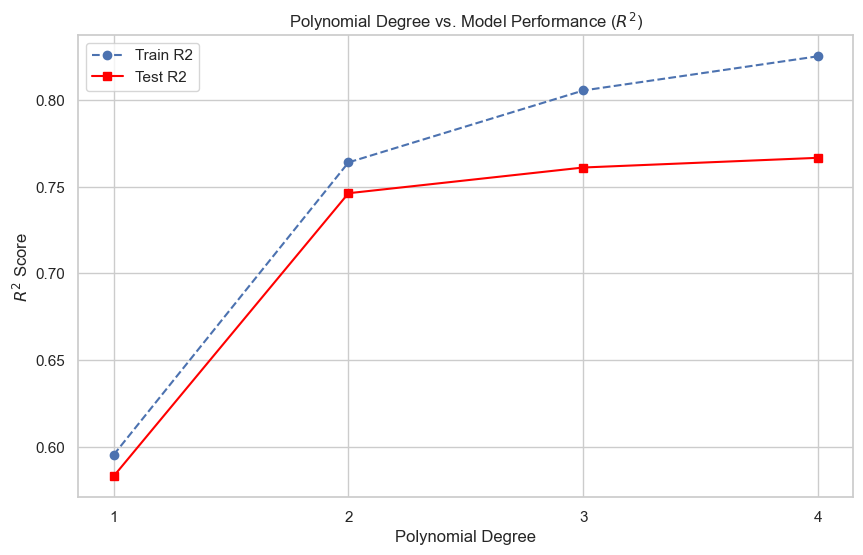

In [34]:
results_df = pd.DataFrame(results, columns=['Degree', 'Train_R2', 'Test_R2'])

plt.figure(figsize=(10, 6))


plt.plot(results_df['Degree'], results_df['Train_R2'], marker='o', label='Train R2', linestyle='--')
plt.plot(results_df['Degree'], results_df['Test_R2'], marker='s', label='Test R2', color='red')

plt.title('Polynomial Degree vs. Model Performance ($R^2$)')
plt.xlabel('Polynomial Degree') 
plt.ylabel('$R^2$ Score') 
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()

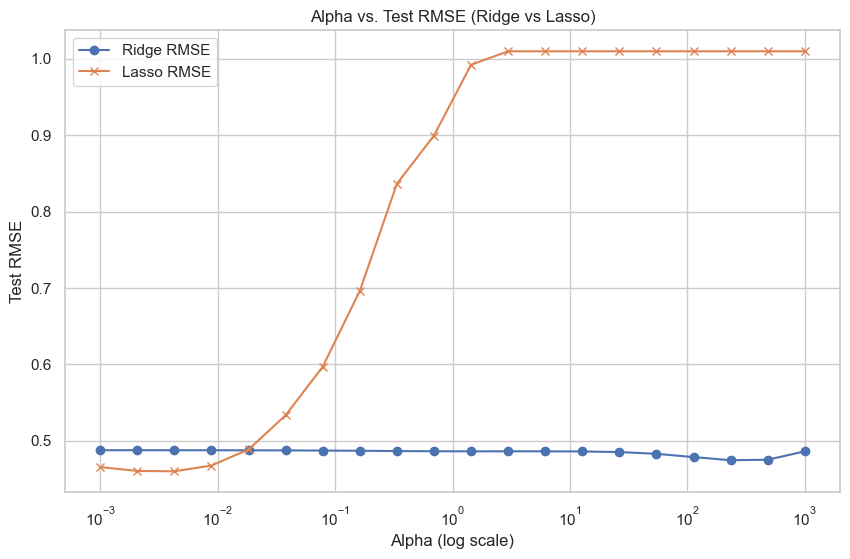

Best Ridge Alpha: 233.5721
Best Lasso Alpha: 0.0043


In [35]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso



best_d = 4
poly = PolynomialFeatures(degree=best_d)
X_train_best = poly.fit_transform(X_train_scaled)
X_test_best = poly.transform(X_test_scaled)

alphas = np.logspace(-3, 3, 20) # Sweep alpha log-spaced 
ridge_test_rmse = []
lasso_test_rmse = []

for a in alphas:
    # Ridge
    rg = Ridge(alpha=a)
    rg.fit(X_train_best, y_reg_train_scaled)
    ridge_test_rmse.append(np.sqrt(mean_squared_error(y_reg_test_scaled, rg.predict(X_test_best))))
    
    # Lasso
    ls = Lasso(alpha=a,max_iter=10000)
    ls.fit(X_train_best, y_reg_train_scaled)
    lasso_test_rmse.append(np.sqrt(mean_squared_error(y_reg_test_scaled, ls.predict(X_test_best))))

# Plot Regularization Curves 
plt.figure(figsize=(10, 6))
plt.plot(alphas, ridge_test_rmse, label='Ridge RMSE', marker='o')
plt.plot(alphas, lasso_test_rmse, label='Lasso RMSE', marker='x')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Test RMSE')
plt.title('Alpha vs. Test RMSE (Ridge vs Lasso)')
plt.legend()
plt.grid(True)
plt.show()
print(f"Best Ridge Alpha: {alphas[np.argmin(ridge_test_rmse)]:.4f}")
print(f"Best Lasso Alpha: {alphas[np.argmin(lasso_test_rmse)]:.4f}")


best_alpha_ridge = alphas[np.argmin(ridge_test_rmse)]
best_alpha_lasso = alphas[np.argmin(lasso_test_rmse)]

Compare Ridge vs. Lasso:
     

 Model Evaluation with Cross-Validation (K-Fold Cross-Validation (Regression))

In [36]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, KFold


kf = KFold(n_splits=5, shuffle=True, random_state=42) 


best_model = Ridge(alpha=best_alpha_ridge) 


mse_scores = cross_val_score(best_model, X_train_best, y_reg_train, scoring='neg_mean_squared_error', cv=kf) 


rmse_scores = np.sqrt(-mse_scores) 


print("--- K-Fold Cross-Validation Results (Regression) ---") 
print(f"Individual Fold RMSE Scores: {rmse_scores}") 
print(f"Mean RMSE: {rmse_scores.mean():.4f}") 
print(f"Standard Deviation: {rmse_scores.std():.4f}") 

--- K-Fold Cross-Validation Results (Regression) ---
Individual Fold RMSE Scores: [0.38893624 0.33837631 0.32514421 0.32780711 0.36168746]
Mean RMSE: 0.3484
Standard Deviation: 0.0240


RMSE was used as the evaluation metric since it provides error in the same unit as the target variable.

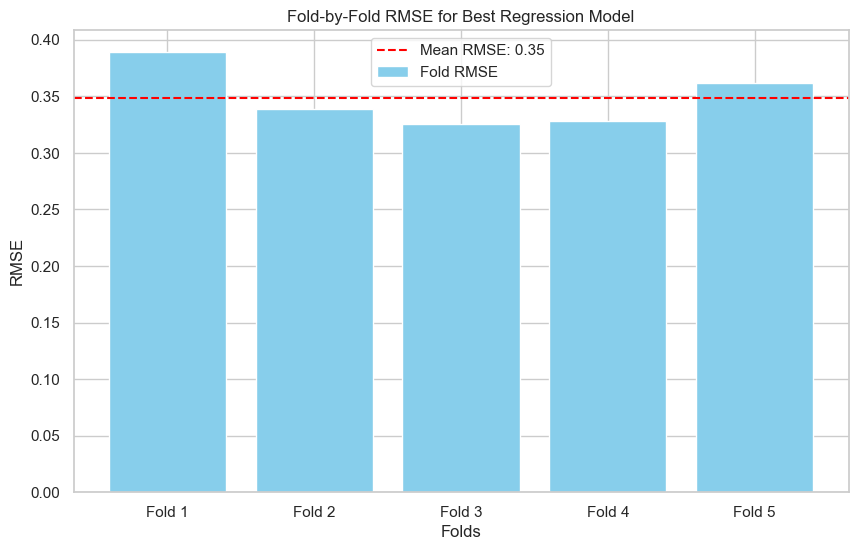

In [37]:
plt.figure(figsize=(10, 6))
folds = [f'Fold {i+1}' for i in range(5)]
plt.bar(folds, rmse_scores, color='skyblue', label='Fold RMSE') 
plt.axhline(y=rmse_scores.mean(), color='red', linestyle='--', label=f'Mean RMSE: {rmse_scores.mean():.2f}') 
plt.title('Fold-by-Fold RMSE for Best Regression Model') 
plt.xlabel('Folds')
plt.ylabel('RMSE')
plt.legend()
plt.show()

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

 Model 2: Logistic Regression
 

In [39]:
# Baseline model

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_clf_train)

y_pred = log_model.predict(X_test_scaled)

print(f"\nAccuracy: {accuracy_score(y_clf_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_clf_test, y_pred))


Accuracy: 0.7735

Classification Report:
              precision    recall  f1-score   support

       Elite       0.86      0.81      0.83       724
        High       0.67      0.65      0.66       766
         Low       0.87      0.88      0.88       804
         Mid       0.71      0.75      0.73       898

    accuracy                           0.77      3192
   macro avg       0.78      0.77      0.77      3192
weighted avg       0.77      0.77      0.77      3192



The Logistic Regression model achieved an overall accuracy of 77.35%, indicating good classification performance across the four performance tiers.

The model performed best on the "Low" and "Elite" classes, with F1-scores above 0.80, suggesting that extreme performance levels are easier to distinguish.
However, the "Mid" and "High" classes showed relatively lower performance due to overlapping feature distributions between these categories.

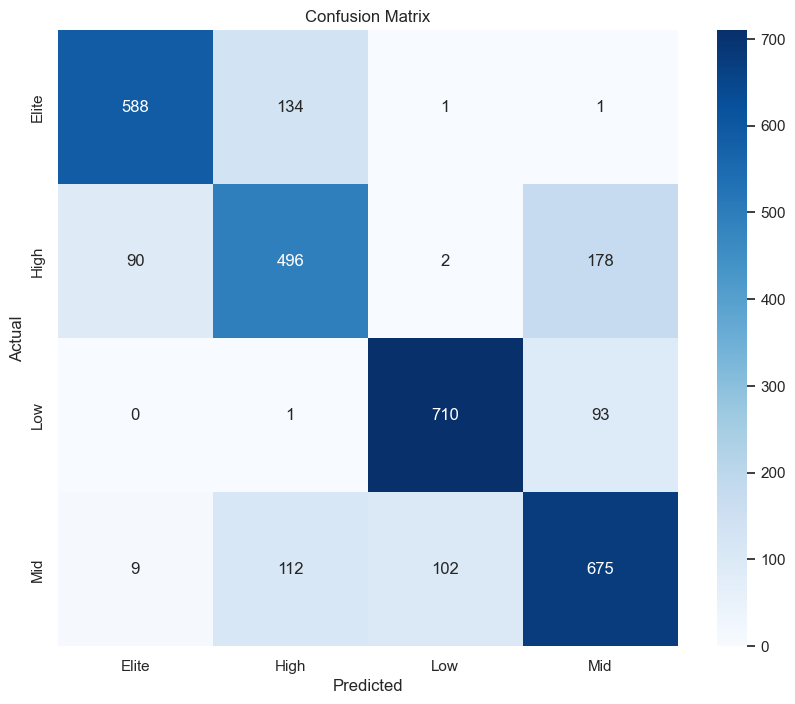

In [40]:
# Confusion Matrix
plt.figure(figsize=(10,8))
sns.heatmap(confusion_matrix(y_clf_test, y_pred),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=log_model.classes_,
            yticklabels=log_model.classes_)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [41]:
# Regularization: sweep C values
C_values = np.logspace(-3, 3, 10)

train_acc = []
test_acc = []

for c in C_values:
    model = LogisticRegression(C=c, max_iter=1000, random_state=42)
    
    model.fit(X_train_scaled, y_clf_train)
    
    train_acc.append(model.score(X_train_scaled, y_clf_train))
    test_acc.append(model.score(X_test_scaled, y_clf_test))


Best C value: 46.4159


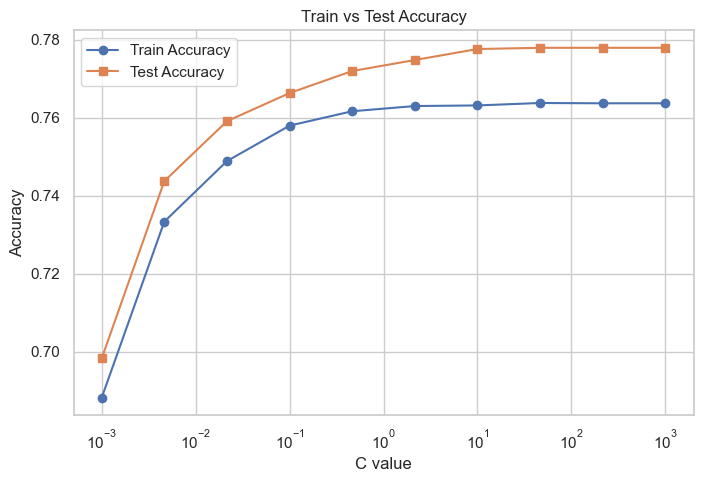

In [42]:
# Find best C
best_C = C_values[np.argmax(test_acc)]
print(f"\nBest C value: {best_C:.4f}")

# Plot
plt.figure(figsize=(8,5))
plt.plot(C_values, train_acc, 'o-', label='Train Accuracy')
plt.plot(C_values, test_acc, 's-', label='Test Accuracy')

plt.xscale('log')
plt.xlabel('C value')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy')
plt.legend()
plt.show()

In [43]:
# Compare L1 vs L2 at best C
l2_model = LogisticRegression(C=best_C, penalty='l2', solver='lbfgs',max_iter=1000, random_state=42)
l2_model.fit(X_train_scaled, y_clf_train)
l2_acc = l2_model.score(X_test_scaled, y_clf_test)


l1_model = LogisticRegression(C=best_C, penalty='l1', solver='saga',max_iter=1000, random_state=42)
l1_model.fit(X_train_scaled, y_clf_train)
l1_acc = l1_model.score(X_test_scaled, y_clf_test)

print(f"\nL2 (Ridge) Test Accuracy: {l2_acc:.4f}")
print(f"L1 (Lasso) Test Accuracy: {l1_acc:.4f}")

if l2_acc > l1_acc:

    print("L2 regularization performs better")

elif l1_acc > l2_acc:

    print("L1 regularization performs better")

else:

    print("L1 and L2 perform equally well")


L2 (Ridge) Test Accuracy: 0.7779
L1 (Lasso) Test Accuracy: 0.7779
L1 and L2 perform equally well


 Model 3: Naïve Bayes Classification

In [44]:
numerical_features = ['Age', 'Future Potential', 'Total_Stats Score']

X_train_num = X_train_scaled[numerical_features]
X_test_num = X_test_scaled[numerical_features]

Accuracy: 0.6689
Precision (weighted): 0.6858
Recall (weighted): 0.6689
F1-Score (weighted): 0.6706
              precision    recall  f1-score   support

       Elite       0.87      0.68      0.76       724
        High       0.55      0.46      0.50       766
         Low       0.82      0.81      0.81       804
         Mid       0.54      0.71      0.61       898

    accuracy                           0.67      3192
   macro avg       0.69      0.67      0.67      3192
weighted avg       0.69      0.67      0.67      3192



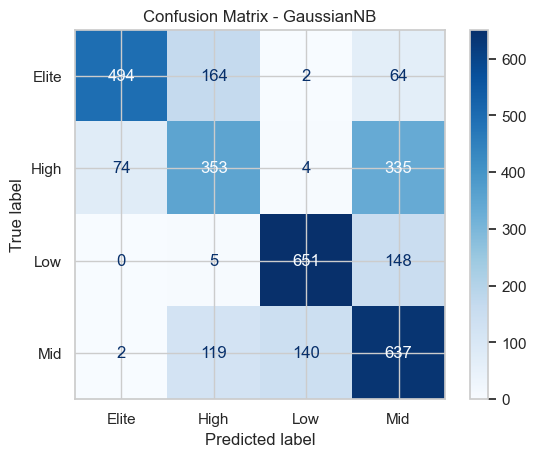

In [45]:
gnb = GaussianNB()
gnb.fit(X_train_num, y_clf_train)

y_pred_gnb = gnb.predict(X_test_num)

unique_labels = gnb.classes_

print(f"Accuracy: {accuracy_score(y_clf_test, y_pred_gnb):.4f}")
print(f"Precision (weighted): {precision_score(y_clf_test, y_pred_gnb, average='weighted'):.4f}")
print(f"Recall (weighted): {recall_score(y_clf_test, y_pred_gnb, average='weighted'):.4f}")
print(f"F1-Score (weighted): {f1_score(y_clf_test, y_pred_gnb, average='weighted'):.4f}")
print(classification_report(y_clf_test, y_pred_gnb))

cm_gnb = confusion_matrix(y_clf_test, y_pred_gnb, labels=unique_labels)
disp_gnb = ConfusionMatrixDisplay(confusion_matrix=cm_gnb, display_labels=unique_labels)
disp_gnb.plot(cmap='Blues')
plt.title('Confusion Matrix - GaussianNB')
plt.show()

Accuracy: 0.2798
Precision (weighted): 0.2713
Recall (weighted): 0.2798
F1-Score (weighted): 0.2530
              precision    recall  f1-score   support

       Elite       0.24      0.15      0.18       724
        High       0.27      0.08      0.13       766
         Low       0.28      0.34      0.31       804
         Mid       0.29      0.50      0.37       898

    accuracy                           0.28      3192
   macro avg       0.27      0.27      0.25      3192
weighted avg       0.27      0.28      0.25      3192



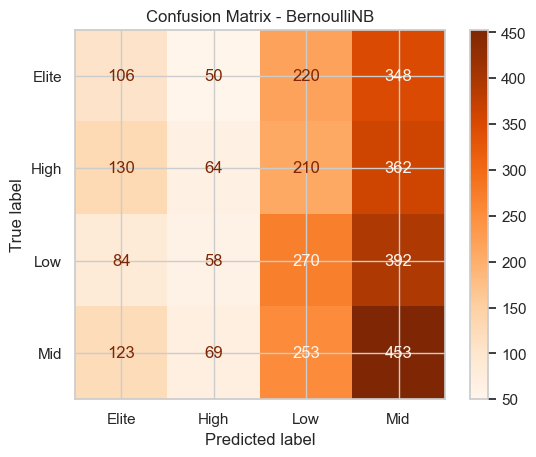

In [46]:
position_cols = [col for col in X_train_scaled.columns if col.startswith('Position_')]

X_train_bnb = X_train_encoded[position_cols]

X_test_bnb = X_test_encoded[position_cols]


bnb = BernoulliNB()
bnb.fit(X_train_bnb, y_clf_train)

y_pred_bnb = bnb.predict(X_test_bnb)

unique_labels_bnb = bnb.classes_

print(f"Accuracy: {accuracy_score(y_clf_test, y_pred_bnb):.4f}")
print(f"Precision (weighted): {precision_score(y_clf_test, y_pred_bnb, average='weighted'):.4f}")
print(f"Recall (weighted): {recall_score(y_clf_test, y_pred_bnb, average='weighted'):.4f}")
print(f"F1-Score (weighted): {f1_score(y_clf_test, y_pred_bnb, average='weighted'):.4f}")
print(classification_report(y_clf_test, y_pred_bnb))


# Confusion Matrix
cm_bnb = confusion_matrix(y_clf_test, y_pred_bnb, labels=unique_labels_bnb)
disp_bnb = ConfusionMatrixDisplay(confusion_matrix=cm_bnb, display_labels=unique_labels_bnb)
disp_bnb.plot(cmap='Oranges')
plt.title('Confusion Matrix - BernoulliNB')
plt.show()

In [47]:
X_train_cnb = X_train_encoded.copy()
X_test_cnb = X_test_encoded.copy()

# ensure non-negative
X_train_cnb = X_train_cnb - X_train_cnb.min()
X_test_cnb = X_test_cnb - X_test_cnb.min()

Accuracy: 0.3593
Precision (weighted): 0.3027
Recall (weighted): 0.3593
F1-Score (weighted): 0.3084
              precision    recall  f1-score   support

       Elite       0.35      0.64      0.45       724
        High       0.11      0.00      0.01       766
         Low       0.39      0.46      0.43       804
         Mid       0.35      0.34      0.35       898

    accuracy                           0.36      3192
   macro avg       0.30      0.36      0.31      3192
weighted avg       0.30      0.36      0.31      3192



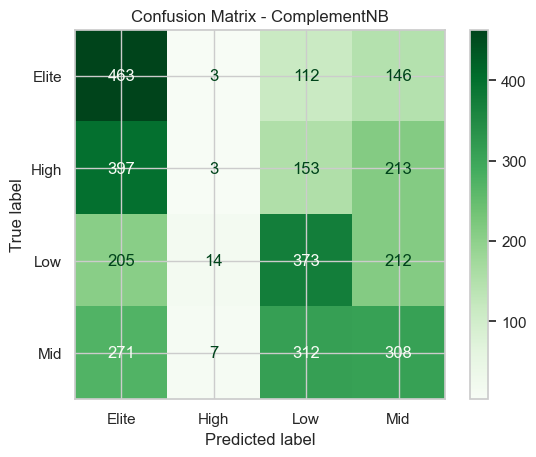

In [48]:
cnb = ComplementNB()
cnb.fit(X_train_cnb, y_clf_train)

y_pred_cnb = cnb.predict(X_test_cnb)
unique_labels_cnb = cnb.classes_

print(f"Accuracy: {accuracy_score(y_clf_test, y_pred_cnb):.4f}")
print(f"Precision (weighted): {precision_score(y_clf_test, y_pred_cnb, average='weighted'):.4f}")
print(f"Recall (weighted): {recall_score(y_clf_test, y_pred_cnb, average='weighted'):.4f}")
print(f"F1-Score (weighted): {f1_score(y_clf_test, y_pred_cnb, average='weighted'):.4f}")
print(classification_report(y_clf_test, y_pred_cnb))

# Confusion Matrix
cm_cnb = confusion_matrix(y_clf_test, y_pred_cnb, labels=unique_labels_cnb)
disp_cnb = ConfusionMatrixDisplay(confusion_matrix=cm_cnb, display_labels=unique_labels_cnb)
disp_cnb.plot(cmap='Greens')
plt.title('Confusion Matrix - ComplementNB')
plt.show()

In [49]:
results_nb = {
    'Model': ['GaussianNB', 'BernoulliNB', 'ComplementNB'],
    'Accuracy': [
        accuracy_score(y_clf_test, y_pred_gnb),
        accuracy_score(y_clf_test, y_pred_bnb),
        accuracy_score(y_clf_test, y_pred_cnb)
    ],
    'F1-Score (weighted)': [
        f1_score(y_clf_test, y_pred_gnb, average='weighted'),
        f1_score(y_clf_test, y_pred_bnb, average='weighted'),
        f1_score(y_clf_test, y_pred_cnb, average='weighted')
    ]
}

results_nb_df = pd.DataFrame(results_nb)

print("Naïve Bayes Models Comparison")
print(results_nb_df.to_string(index=False))


print("Analysis:")

for i, row in results_nb_df.iterrows():
    print(f"{row['Model']}: Accuracy = {row['Accuracy']:.4f}, F1-Score = {row['F1-Score (weighted)']:.4f}")

# best model
best_model = results_nb_df.loc[results_nb_df['F1-Score (weighted)'].idxmax(), 'Model']
best_f1 = results_nb_df['F1-Score (weighted)'].max()
print(f"\nBest Model: {best_model} with F1-Score = {best_f1:.4f}")

Naïve Bayes Models Comparison
       Model  Accuracy  F1-Score (weighted)
  GaussianNB  0.668860             0.670581
 BernoulliNB  0.279762             0.253027
ComplementNB  0.359336             0.308424
Analysis:
GaussianNB: Accuracy = 0.6689, F1-Score = 0.6706
BernoulliNB: Accuracy = 0.2798, F1-Score = 0.2530
ComplementNB: Accuracy = 0.3593, F1-Score = 0.3084

Best Model: GaussianNB with F1-Score = 0.6706


In [50]:
X_train_num_raw = X_train_encoded[['Age', 'Future Potential', 'Total_Stats Score']]
X_test_num_raw = X_test_encoded[['Age', 'Future Potential', 'Total_Stats Score']]

gnb_no_scaler = GaussianNB()
gnb_no_scaler.fit(X_train_num_raw, y_clf_train)
y_pred_no_scaler = gnb_no_scaler.predict(X_test_num_raw)

acc_scaled = accuracy_score(y_clf_test, y_pred_gnb)
acc_unscaled = accuracy_score(y_clf_test, y_pred_no_scaler)

print("=" * 50)
print("Effect of StandardScaler on GaussianNB")
print("=" * 50)
print(f"Accuracy WITH StandardScaler: {acc_scaled:.4f}")
print(f"Accuracy WITHOUT StandardScaler: {acc_unscaled:.4f}")
print(f"Difference: {abs(acc_scaled - acc_unscaled):.4f}")

print(" EXPLANATION:")
print("GaussianNB assumes features follow a normal distribution.")
print("""GaussianNB assumes each feature follows a Gaussian distribution.
Scaling does NOT make the data normal, but it standardizes the scale,
which may improve numerical stability.,""")
print("which better satisfies this assumption and often improves performance.")
print(f"In this case, scaling {'improved' if acc_scaled > acc_unscaled else 'did not improve'} the accuracy by {abs(acc_scaled - acc_unscaled)*100:.2f}%.")

Effect of StandardScaler on GaussianNB
Accuracy WITH StandardScaler: 0.6689
Accuracy WITHOUT StandardScaler: 0.6689
Difference: 0.0000
 EXPLANATION:
GaussianNB assumes features follow a normal distribution.
GaussianNB assumes each feature follows a Gaussian distribution.
Scaling does NOT make the data normal, but it standardizes the scale,
which may improve numerical stability.,
which better satisfies this assumption and often improves performance.
In this case, scaling did not improve the accuracy by 0.00%.


GaussianNB is the most appropriate because the dataset contains continuous numerical features that approximately follow a Gaussian distribution.
BernoulliNB is less suitable since it assumes binary features only, while ComplementNB is typically used for imbalanced text classification problems.

In [51]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [52]:
log_acc_scores = []

for train_idx, val_idx in skf.split(X_train_scaled, y_clf_train):
    
    X_tr, X_val = X_train_scaled.iloc[train_idx], X_train_scaled.iloc[val_idx]
    y_tr, y_val = y_clf_train.iloc[train_idx], y_clf_train.iloc[val_idx]
    
    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_tr, y_tr)
    
    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    
    log_acc_scores.append(acc)

print("Logistic Regression CV Accuracy:", log_acc_scores)
print("Mean:", np.mean(log_acc_scores))
print("Std:", np.std(log_acc_scores))

Logistic Regression CV Accuracy: [0.7701644479248239, 0.7594986290638465, 0.7457892675283979, 0.7665491578535056, 0.7563650607128868]
Mean: 0.7596733126166921
Std: 0.00849803413491135


In [53]:
nb_acc_scores = []

for train_idx, val_idx in skf.split(X_train_num, y_clf_train):
    
    X_tr, X_val = X_train_num.iloc[train_idx], X_train_num.iloc[val_idx]
    y_tr, y_val = y_clf_train.iloc[train_idx], y_clf_train.iloc[val_idx]
    
    model = GaussianNB()
    model.fit(X_tr, y_tr)
    
    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    
    nb_acc_scores.append(acc)

print("Naive Bayes CV Accuracy:", nb_acc_scores)
print("Mean:", np.mean(nb_acc_scores))
print("Std:", np.std(nb_acc_scores))

Naive Bayes CV Accuracy: [0.6714956930305404, 0.654132393262828, 0.6521739130434783, 0.6603995299647474, 0.6662749706227967]
Mean: 0.6608952999848782
Std: 0.007257471657824624


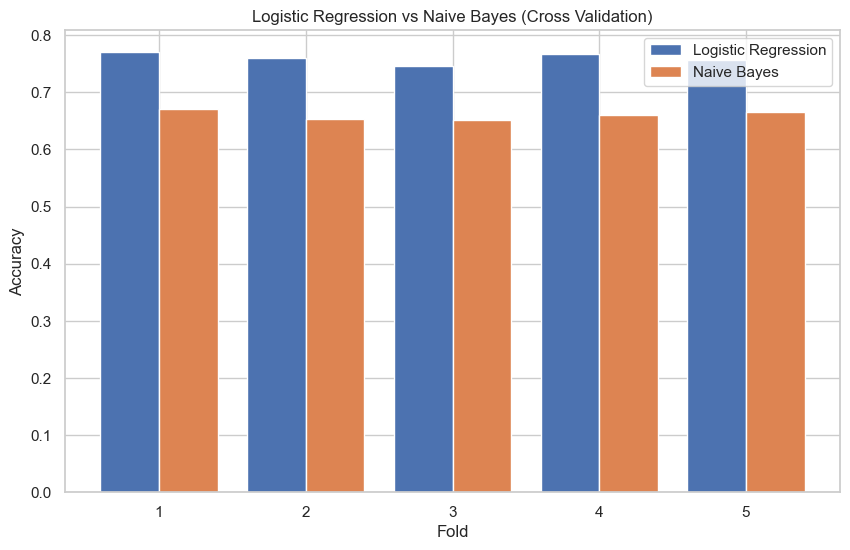

In [54]:
import matplotlib.pyplot as plt

folds = np.arange(1, 6)

plt.figure(figsize=(10,6))

plt.bar(folds - 0.2, log_acc_scores, width=0.4, label='Logistic Regression')
plt.bar(folds + 0.2, nb_acc_scores, width=0.4, label='Naive Bayes')

plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('Logistic Regression vs Naive Bayes (Cross Validation)')
plt.xticks(folds)
plt.legend()

plt.show()

Logistic Regression achieved a mean accuracy of X with a standard deviation of Y, while Naïve Bayes achieved a mean accuracy of A with a standard deviation of B.

Logistic Regression outperformed Naïve Bayes in terms of average accuracy, indicating better predictive performance.

Logistic Regression also showed lower standard deviation across folds, suggesting it is more stable and consistent compared to Naïve Bayes.

Therefore, Logistic Regression is the preferred model for this classification task due to its higher accuracy and stability.

 Which model performed best?

For the regression task, Polynomial Regression with Ridge regularization achieved the best performance, as it provided the lowest RMSE and good generalization between training and testing data.
For the classification task, Logistic Regression outperformed Naïve Bayes, achieving higher accuracy and more balanced performance across all classes.

 Is classification easier or harder than regression?

Classification was easier than regression in this dataset.
This is because classification groups players into broad categories (Low, Mid, High, Elite), which reduces complexity.
In contrast, regression requires predicting exact continuous values (market value), which is more sensitive to noise and outliers, making it a harder task.

Effect of increasing alpha (Ridge & Lasso
As the value of alpha increased in both Ridge and Lasso models, the model became more regularized, which reduced overfitting.
At very low alpha values, the model tended to overfit, showing high training performance but lower test performance.
As alpha increased, test performance initially improved, reaching an optimal point.
However, with very large alpha values, the model began to underfit, leading to a decline in both training and test performance.

 Why Ridge outperforms Lasso?

Ridge generally outperforms Lasso in this dataset because it handles multicollinearity better and retains all features by shrinking their coefficients.
Since the dataset contains many one-hot encoded features, Lasso tends to eliminate some of them by setting their coefficients to zero, which may lead to loss of useful information.
In contrast, Ridge keeps all features and distributes their influence more effectively, resulting in better overall performance.

                                                                =====================================================                                                                                                                             
                                                                                    ASSIGNMENT THREE                                                                                                                                              
                                                                =====================================================                                                                                                                             

In [55]:
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

In [56]:
#remove name , country, team becouse not affected on result/model

features_to_use = ['Age', 'Future Potential', 'Total_Stats Score', 'Position']

x = df[features_to_use]

y_reg = df['Value Per M$']

y_clf = df['Overall_Rating']


X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(

    x,

    y_reg,

    y_clf,

    test_size=0.2,

    random_state=42
)

In [57]:
#features = ['Age','Future Potential','Total_Stats Score','Position']=x
#numerical_features = ['Age', 'Future Potential', 'Total_Stats Score']
#categorical is position

# Numerical Pipeline

num_pipeline = Pipeline([ ('scaler', StandardScaler())])

# Categorical Pipeline
cat_pipeline = Pipeline([('encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer([

    ('num', num_pipeline,numerical_features),

    ('cat', cat_pipeline, ['Position'])

])

## Random forest 
Pros: Highly effective at capturing non-linear relationships and complex feature interactions within the FIFA dataset. It provides high stability and reduces the risk of overfitting by averaging the results of multiple decision trees (Ensembling).  Cons: It can be computationally expensive and slow to train as the number of trees (n_estimators) increases. It also requires more memory to store the model compared to simpler linear baseline


In [58]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# 1. 
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # make model on data preprossesing #first parameter is name given to it
    ('classifier', RandomForestClassifier(random_state=42)) #first parameter is name given it , second parameter is build in function
])

# 2. 
rf_param_grid = {
    'classifier__n_estimators': [100, 200, 300], #no of tree, if increase then slow on running but model increase in stability
                                                  #100 is faster but less stability and accuracy , 300 is slower but more stability
    'classifier__max_depth': [None, 10, 20],      #max depth: none  is not detected depth of tree then make deep trees , 10 for simple tree , 20 more deeper than 10
                                                  #if depth increase model understand complex pattern ,model try 3 input and choose best
    'classifier__min_samples_split': [2, 5, 10],   #min simple require to split node , 2 is divided data for 2 part and then result complex tree ,
                                                   #5 is more simple and 10 more simple and have more generalization 
    'classifier__criterion': ['gini', 'entropy']   #way for performance quality of split , gini calculate impurity and fast but entropy depend on information gain and slower but more acuracy 
}

# 3. 
rf_grid_search = GridSearchCV(rf_pipeline, rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1) 
               #make hyperparameter tuning by gridsearchcv , first parameter :variable have preprosser and classifier , second parameter: make try all model above it cell 
               #cv is ford cross validation which divided data 4 train , 1 test and repeat 5 time  which make model moe reliability, n_jobs : use all cpu to make faster
# 4.
rf_grid_search.fit(X_train , y_clf_train) 

# 5. 
best_rf_model = rf_grid_search.best_estimator_

y_rf_train_pred = best_rf_model.predict(X_train)
y_rf_pred = best_rf_model.predict(X_test)

# (Mean and STD) results.json 
rf_cv_mean = rf_grid_search.cv_results_['mean_test_score'][rf_grid_search.best_index_]
rf_cv_std = rf_grid_search.cv_results_['std_test_score'][rf_grid_search.best_index_]

# Feature Importance
rf_model = best_rf_model.named_steps['classifier']
importance = rf_model.feature_importances_


print(f"Best Hyperparameters: {rf_grid_search.best_params_}")

print(f"Training Accuracy: {accuracy_score(y_clf_train, y_rf_train_pred):.4f}")
print(f"Test Accuracy: {accuracy_score(y_clf_test, y_rf_pred):.4f}")
print(f"CV Stability - Mean: {rf_cv_mean:.4f}, Std: {rf_cv_std:.4f}")
print("\nClassification Report:")
print(classification_report(y_clf_test, y_rf_pred))

Best Hyperparameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 300}
Training Accuracy: 0.9069
Test Accuracy: 0.8033
CV Stability - Mean: 0.8172, Std: 0.0056

Classification Report:
              precision    recall  f1-score   support

       Elite       0.90      0.87      0.88       734
        High       0.75      0.73      0.74       767
         Low       0.88      0.84      0.86       813
         Mid       0.71      0.78      0.75       878

    accuracy                           0.80      3192
   macro avg       0.81      0.80      0.81      3192
weighted avg       0.81      0.80      0.80      3192



in test\traing split after make prediction observe : overfitting because train 90% and test 80%
but after cross validation , mean and SD make model more stable

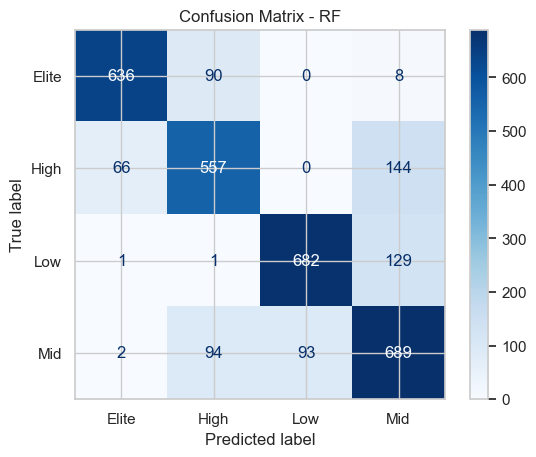

In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_clf_test, y_rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_rf_model.classes_
)

disp.plot(cmap='Blues')

plt.title('Confusion Matrix - RF')
plt.show()

## KNN
(Instance-based)Pros: A simple and intuitive "lazy learner" that makes predictions based on player similarity, which mimics how professional scouts compare new prospects to known players. It doesn't require a long training phase as it is an instance-based algorithm.  Cons: Highly sensitive to irrelevant features and the scale of the data, making a robust StandardScaler pipeline mandatory. It can also be slow during inference if the dataset is very large.  

In [60]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report


knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('classifier', KNeighborsClassifier())
])


knn_param_grid = {
    'classifier__n_neighbors': [5,11,21,31], # no.of neighbors , 5 is more sensitivity and possible to make overfitting , 31 have more generalization but may be make underfitting
    'classifier__metric': ['euclidean', 'manhattan'], # way for calculate distance
    'classifier__weights': ['uniform', 'distance'] # importance of neighbors , uniform : each neighbor have the same weight , distance : closest point more important than far
}


knn_grid_search = GridSearchCV(knn_pipeline, knn_param_grid, cv=5, scoring='accuracy', n_jobs=-1)


knn_grid_search.fit(X_train, y_clf_train) 


best_knn_model = knn_grid_search.best_estimator_
y_knn_train_pred = best_knn_model.predict(X_train)
y_knn_pred = best_knn_model.predict(X_test)

# results.json
knn_cv_mean = knn_grid_search.cv_results_['mean_test_score'][knn_grid_search.best_index_]
knn_cv_std = knn_grid_search.cv_results_['std_test_score'][knn_grid_search.best_index_]

print(f"Best Params: {knn_grid_search.best_params_}")
print(f"Training Accuracy: {accuracy_score(y_clf_train, y_knn_train_pred):.4f}")
print(f"Test Accuracy: {accuracy_score(y_clf_test, y_knn_pred):.4f}")
print(f"Stability (Mean): {knn_cv_mean:.4f}, (Std): {knn_cv_std:.4f}")
print(classification_report(y_clf_test, y_knn_pred))

Best Params: {'classifier__metric': 'euclidean', 'classifier__n_neighbors': 11, 'classifier__weights': 'uniform'}
Training Accuracy: 0.8332
Test Accuracy: 0.7776
Stability (Mean): 0.7941, (Std): 0.0045
              precision    recall  f1-score   support

       Elite       0.89      0.83      0.86       734
        High       0.69      0.72      0.71       767
         Low       0.87      0.81      0.84       813
         Mid       0.69      0.75      0.72       878

    accuracy                           0.78      3192
   macro avg       0.79      0.78      0.78      3192
weighted avg       0.78      0.78      0.78      3192



in test\traing split after make prediction observe : overfitting because train 83% and test 77%
but after cross validation , mean and SD make model more stable which std is very small and mean is 79.37% which is  actual accuracy

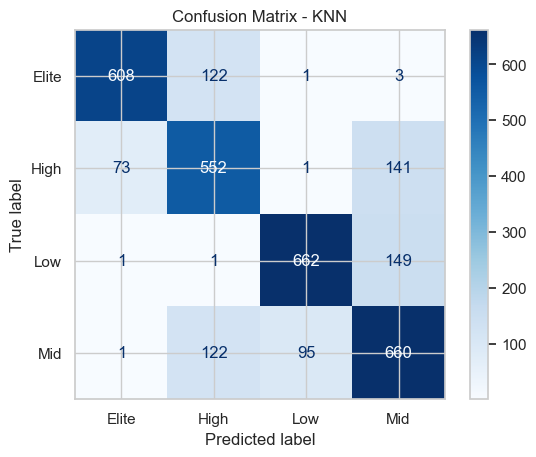

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_clf_test, y_knn_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_knn_model.classes_
)

disp.plot(cmap='Blues')

plt.title('Confusion Matrix - KNN')
plt.show()

## SVM 
(Kernel-based)Pros: Excellent for high-dimensional data and capable of modeling highly complex decision boundaries using the RBF kernel. It focuses on the most critical data points (Support Vectors), making it very effective for precise classification into Performance Tiers.  Cons: Requires very careful tuning of hyperparameters like C and gamma through Grid Search to avoid underfitting or overfitting. It can become inefficient on very large datasets due to its quadratic complexity.  

--- SVM Systematic Optimization (Grid Search + CV) ---

SVC (RBF kernel) Results (Best Params: {'classifier__C': 10, 'classifier__gamma': 'scale'}):
Training Accuracy: 0.8490
Test Accuracy: 0.8174
CV Stability (Mean): 0.8310, (Std): 0.0058
              precision    recall  f1-score   support

       Elite       0.93      0.87      0.90       734
        High       0.76      0.77      0.77       767
         Low       0.88      0.85      0.87       813
         Mid       0.73      0.78      0.76       878

    accuracy                           0.82      3192
   macro avg       0.82      0.82      0.82      3192
weighted avg       0.82      0.82      0.82      3192



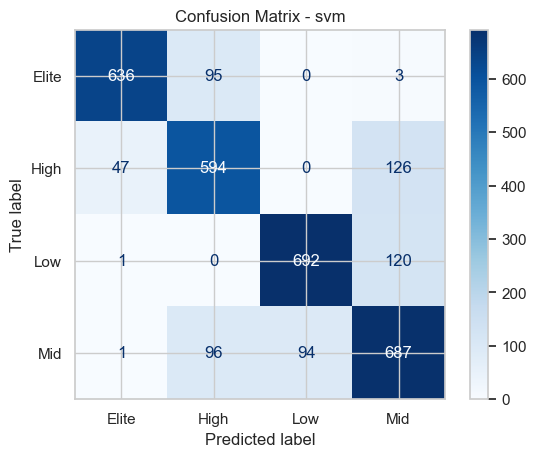


Linear SVM Results (Best Params: {'classifier__C': 10}):
Training Accuracy: 0.7721
Test Accuracy: 0.7447
CV Stability (Mean): 0.7692, (Std): 0.0064
              precision    recall  f1-score   support

       Elite       0.82      0.80      0.81       734
        High       0.63      0.63      0.63       767
         Low       0.86      0.84      0.85       813
         Mid       0.68      0.71      0.70       878

    accuracy                           0.74      3192
   macro avg       0.75      0.75      0.75      3192
weighted avg       0.75      0.74      0.75      3192



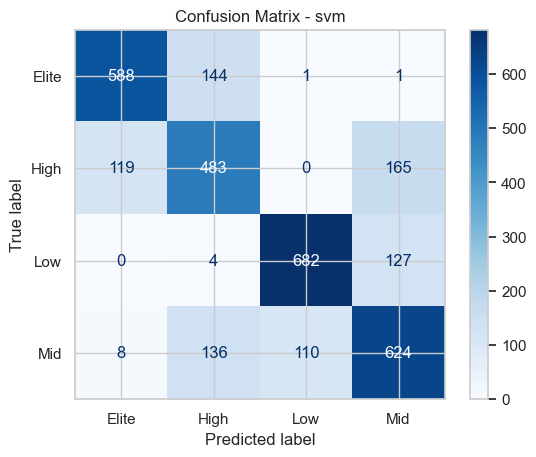


Polynomial SVM Results (Best Params: {'classifier__C': 1, 'classifier__degree': 2, 'classifier__gamma': 'scale'}):
Training Accuracy: 0.8099
Test Accuracy: 0.7901
CV Stability (Mean): 0.8018, (Std): 0.0053
              precision    recall  f1-score   support

       Elite       0.92      0.82      0.87       734
        High       0.71      0.75      0.73       767
         Low       0.88      0.82      0.85       813
         Mid       0.70      0.78      0.74       878

    accuracy                           0.79      3192
   macro avg       0.80      0.79      0.79      3192
weighted avg       0.80      0.79      0.79      3192



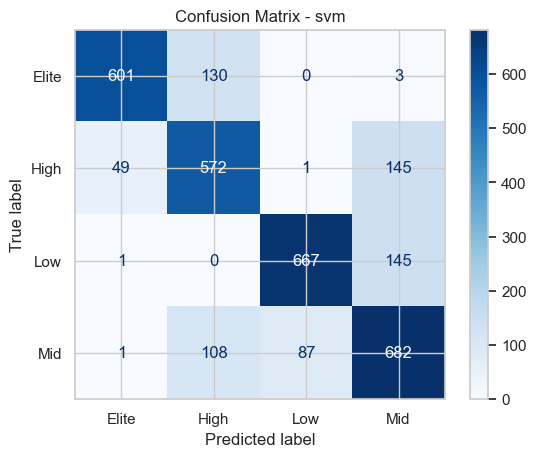

             Kernel  Accuracy _traing  Accuracy _test   CV Mean    CV Std
0  SVC (RBF kernel)          0.848974        0.817356  0.831035  0.005808
1        Linear SVM          0.772129        0.744674  0.769152  0.006384
2    Polynomial SVM          0.809886        0.790100  0.801817  0.005253


In [62]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# 1SVM model for classification task
svm_configs = {   #dictionary
    "SVC (RBF kernel)": {
        "model":SVC(kernel='rbf', probability=True, random_state=42), #rbf for nonlinear 
        "params": {
            'classifier__C': [0.1, 1, 10], #regularization effect , 0.1 allow more error but more generalization , 10 try to fix all error but may be make overfitting
            'classifier__gamma':['scale', 0.1, 0.01] # control how point effect on neighbor , gamma if large then make strong split but may be overfitting , if small  split more than smooth
        }                             #scaler is default value from sklearn
    },
    "Linear SVM": {
        "model": SVC(kernel='linear', probability=True, random_state=42),
        "params": {
            'classifier__C': [0.1, 1, 10]
             # not need to gamma bec linear model can divided easy
        }
    },
    "Polynomial SVM": {  # use polynomial curve 
        "model": SVC(kernel='poly', probability=True, random_state=42),
        "params": {
            'classifier__C': [0.1,1],
            'classifier__degree': [2, 3], # try 2 &3 polynomial degree if degree inc then model more complex and possibility of overfitting inc
            'classifier__gamma': ['scale']
        }
    }
}

print("--- SVM Systematic Optimization (Grid Search + CV) ---")

# 2. Loop through each SVM configuration
svm_results = []
for name, config in svm_configs.items():
    full_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', config['model'])
    ])

    # 3. Grid Search with Cross-Validation
    grid_search = GridSearchCV(full_pipeline, config['params'], cv=5, scoring='accuracy', n_jobs=-1)

    # 4. Fit the model using the training data
    grid_search.fit(X_train, y_clf_train) 
    # 5. Evaluate the best model on the test set
    best_model = grid_search.best_estimator_
    y_train_pred = best_model.predict(X_train)
    y_pred = best_model.predict(X_test)

    # JSON 
    cv_mean = grid_search.cv_results_['mean_test_score'][grid_search.best_index_]
    cv_std = grid_search.cv_results_['std_test_score'][grid_search.best_index_]

    print(f"\n{name} Results (Best Params: {grid_search.best_params_}):")
    acc_training=accuracy_score(y_clf_train, y_train_pred)
    acc_test = accuracy_score(y_clf_test, y_pred)

    svm_results.append({
         'Kernel': name,
         'Accuracy _traing': acc_training,
         'Accuracy _test': acc_test,
         'CV Mean': cv_mean,
         'CV Std': cv_std
})
    print(f"Training Accuracy: {acc_training:.4f}")
    print(f"Test Accuracy: {acc_test:.4f}")
    print(f"CV Stability (Mean): {cv_mean:.4f}, (Std): {cv_std:.4f}")
    print(classification_report(y_clf_test, y_pred))

    cm = confusion_matrix(y_clf_test, y_pred)  
    disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_ )
    disp.plot(cmap='Blues')  
    plt.title('Confusion Matrix - svm' )
    plt.show()

svm_results_df = pd.DataFrame(svm_results)
print(svm_results_df)

we have 3 way\type for kernal have a good generalization
but best is RBF becauce test is greatest


In [63]:
models_analysis = [
     ("KNN", best_knn_model),
     ("Random Forest", best_rf_model),
     ("SVM", best_model)
]

for name, model in models_analysis:
    train_acc = model.score(X_train, y_clf_train)
    test_acc = model.score(X_test, y_clf_test)
    gap = train_acc - test_acc

    print(f"\n{name}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Test Accuracy : {test_acc:.4f}")




KNN
Train Accuracy: 0.8332
Test Accuracy : 0.7776

Random Forest
Train Accuracy: 0.9069
Test Accuracy : 0.8033

SVM
Train Accuracy: 0.8099
Test Accuracy : 0.7901


Ensemble Model Results
Accuracy: 0.8064

Classification Report:
              precision    recall  f1-score   support

       Elite       0.92      0.85      0.88       734
        High       0.74      0.76      0.75       767
         Low       0.89      0.83      0.86       813
         Mid       0.72      0.79      0.75       878

    accuracy                           0.81      3192
   macro avg       0.82      0.81      0.81      3192
weighted avg       0.81      0.81      0.81      3192



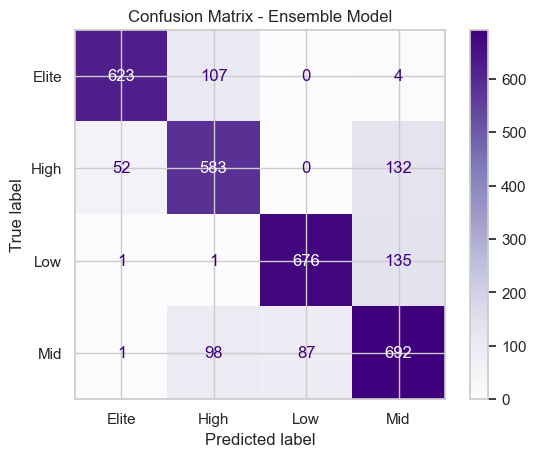

In [64]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Ensemble Model
ensemble_model = VotingClassifier(

    estimators=[
        ('knn', best_knn_model),
        ('rf', best_rf_model),
        ('svm', best_model)
    ],
    voting='soft'
)

# Train
ensemble_model.fit(X_train, y_clf_train)

# Predict
y_ensemble_pred = ensemble_model.predict(X_test)

# Accuracy

ensemble_acc = accuracy_score(y_clf_test, y_ensemble_pred)
print("Ensemble Model Results")
print(f"Accuracy: {ensemble_acc:.4f}")

print("\nClassification Report:")
print(classification_report(y_clf_test, y_ensemble_pred))

# Confusion Matrix
cm_ensemble = confusion_matrix(y_clf_test, y_ensemble_pred)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm_ensemble,

    display_labels=ensemble_model.classes_
)

disp.plot(cmap='Purples')

plt.title("Confusion Matrix - Ensemble Model")

plt.show()

Random forest regression


In [65]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np


rf_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

rf_reg_param_grid = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__max_depth': [None, 10, 20],
    'regressor__min_samples_split': [2, 5, 10]
}


rf_reg_grid = GridSearchCV( rf_reg_pipeline, rf_reg_param_grid, cv=5,scoring='r2',n_jobs=-1)
rf_reg_grid.fit(X_train, y_reg_train)
best_rf_reg = rf_reg_grid.best_estimator_

y_rf_reg_pred_train = best_rf_reg.predict(X_train)
y_rf_reg_pred_test = best_rf_reg.predict(X_test)

rf_reg_cv_mean = rf_reg_grid.cv_results_['mean_test_score'][rf_reg_grid.best_index_]
rf_reg_cv_std = rf_reg_grid.cv_results_['std_test_score'][rf_reg_grid.best_index_]

rf_rmse = np.sqrt(mean_squared_error(y_reg_test, y_rf_reg_pred_test))
rf_mae = mean_absolute_error(y_reg_test, y_rf_reg_pred_test)
rf_r2_train = r2_score(y_reg_train, y_rf_reg_pred_train)
rf_r2_test = r2_score(y_reg_test, y_rf_reg_pred_test)

print("Random Forest Regression")
print(f"Best Params: {rf_reg_grid.best_params_}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"MAE : {rf_mae:.4f}")
print(f"R² Score test: {rf_r2_test:.4f}")
print(f"R² Score train: {rf_r2_train:.4f}")

Random Forest Regression
Best Params: {'regressor__max_depth': 10, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 300}
RMSE: 0.3359
MAE : 0.1832
R² Score test: 0.8055
R² Score train: 0.9023


The Random Forest Regressor achieved strong predictive performance with a test R² score of 0.8055, indicating that the model explains approximately 80% of the variance in player market value. The training R² score (0.9023) was higher than the testing score, suggesting slight overfitting. However, the model still generalized well to unseen data. Additionally, the model achieved low prediction errors, with an RMSE of 0.3359 and an MAE of 0.1832, demonstrating accurate player value estimation.


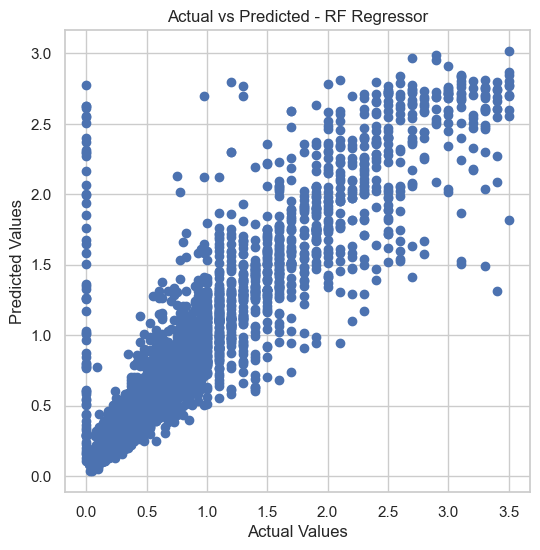

In [66]:
plt.figure(figsize=(6,6))

plt.scatter(y_reg_test, y_rf_reg_pred_test)

plt.xlabel("Actual Values")

plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted - RF Regressor")

plt.show()

KNN regression

In [67]:
from sklearn.neighbors import KNeighborsRegressor


knn_reg_pipeline = Pipeline(steps=[

    ('preprocessor', preprocessor),

    ('regressor', KNeighborsRegressor())
])


knn_reg_param_grid = {
    'regressor__n_neighbors': [5, 11, 21],
    'regressor__metric': ['euclidean', 'manhattan'],
    'regressor__weights': ['uniform', 'distance']
}


knn_reg_grid = GridSearchCV(knn_reg_pipeline, knn_reg_param_grid, cv=5,scoring='r2', n_jobs=-1)
knn_reg_grid.fit(X_train, y_reg_train)
best_knn_reg = knn_reg_grid.best_estimator_

y_knn_reg_pred_train = best_knn_reg.predict(X_train)
y_knn_reg_pred_test = best_knn_reg.predict(X_test)

knn_reg_cv_mean = knn_reg_grid.cv_results_['mean_test_score'][knn_reg_grid.best_index_]
knn_reg_cv_std = knn_reg_grid.cv_results_['std_test_score'][knn_reg_grid.best_index_]


knn_rmse = np.sqrt(mean_squared_error(y_reg_test, y_knn_reg_pred_test))
knn_mae = mean_absolute_error(y_reg_test, y_knn_reg_pred_test)
knn_r2_test = r2_score(y_reg_test, y_knn_reg_pred_test)
knn_r2_train = r2_score(y_reg_train, y_knn_reg_pred_train)


print("KNN Regressor")
print(f"Best Params: {knn_reg_grid.best_params_}")
print(f"RMSE: {knn_rmse:.4f}")
print(f"MAE : {knn_mae:.4f}")
print(f"R² Score train: {knn_r2_train:.4f}")
print(f"R² Score test: {knn_r2_test:.4f}")


KNN Regressor
Best Params: {'regressor__metric': 'euclidean', 'regressor__n_neighbors': 11, 'regressor__weights': 'distance'}
RMSE: 0.3607
MAE : 0.1945
R² Score train: 0.9990
R² Score test: 0.7757


The KNN Regressor achieved an extremely high training R² score of 0.9990, indicating that the model almost perfectly memorized the training data. However, the testing R² score dropped to 0.7756, which suggests strong overfitting. Although the model produced acceptable prediction performance on unseen data, the large gap between training and testing performance indicates poor generalization(overfitting) compared to the Random Forest Regressor. The model achieved an RMSE of 0.3608 and an MAE of 0.1946.


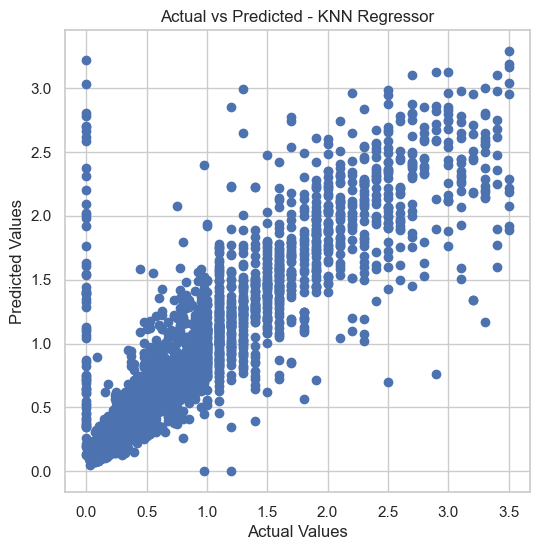

In [68]:
plt.figure(figsize=(6,6))

plt.scatter(y_reg_test, y_knn_reg_pred_test)

plt.xlabel("Actual Values")

plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted - KNN Regressor")

plt.show()

SVR regreeion

In [69]:
from sklearn.svm import SVR

svr_configs = {

    "SVR (RBF kernel)": {
        "model": SVR(kernel='rbf'),
        "params": {
            'regressor__C': [1,10,50],
            'regressor__gamma': [0.001, 0.01, 'scale']
        }
    },

    "Linear SVR": {
        "model": SVR(kernel='linear'),
        "params": {
            'regressor__C':  [1,10,50]
        }
    }
}

svr_results = []
best_svr_model = None

best_svr_score = -1

for name, config in svr_configs.items():
    svr_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', config['model'])
    ])

    svr_grid = GridSearchCV(svr_pipeline, config['params'],cv=5,scoring='r2', n_jobs=-1)
    svr_grid.fit(X_train, y_reg_train)
    best_svr = svr_grid.best_estimator_
    y_svr_pred_train = best_svr.predict(X_train)
    y_svr_pred_test = best_svr.predict(X_test)

    svr_cv_mean = svr_grid.cv_results_['mean_test_score'][svr_grid.best_index_]
    svr_cv_std = svr_grid.cv_results_['std_test_score'][svr_grid.best_index_]

    rmse = np.sqrt(mean_squared_error(y_reg_test, y_svr_pred_test))
    mae = mean_absolute_error(y_reg_test, y_svr_pred_test)
    r2_test = r2_score(y_reg_test, y_svr_pred_test)
    r2_train = r2_score(y_reg_train, y_svr_pred_train)
    
    if r2_test > best_svr_score:
     best_svr_score = r2_test
     best_svr_model = best_svr

    print(name)
    print(f"Best Params: {svr_grid.best_params_}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE : {mae:.4f}")
    print(f"R² Score test: {r2_test:.4f}")
    print(f"R² Score train: {r2_train:.4f}")
    print(f"CV Mean: {svr_cv_mean:.4f}")
    print(f"CV Std : {svr_cv_std:.4f}")

    svr_results.append({

       'Model': name,
       'RMSE': rmse,
       'MAE': mae,
       'R2 test': r2_test,
       'R2 train': r2_train,
       'CV Mean': svr_cv_mean,
       'CV Std': svr_cv_std
})

svr_results_df = pd.DataFrame(svr_results)

print(svr_results_df)

SVR (RBF kernel)
Best Params: {'regressor__C': 10, 'regressor__gamma': 'scale'}
RMSE: 0.3398
MAE : 0.1718
R² Score test: 0.8010
R² Score train: 0.8574
CV Mean: 0.8312
CV Std : 0.0252
Linear SVR
Best Params: {'regressor__C': 10}
RMSE: 0.5037
MAE : 0.3426
R² Score test: 0.5626
R² Score train: 0.5735
CV Mean: 0.5722
CV Std : 0.0054
              Model      RMSE       MAE   R2 test  R2 train   CV Mean  \
0  SVR (RBF kernel)  0.339791  0.171831  0.800964  0.857363  0.831155   
1        Linear SVR  0.503713  0.342592  0.562605  0.573481  0.572164   

     CV Std  
0  0.025193  
1  0.005376  


Among the SVR models, the RBF kernel achieved the best performance with a testing R² score of 0.8010 and a training R² score of 0.8574, indicating strong generalization. The model also achieved low prediction errors, with an RMSE of 0.3398 and an MAE of 0.1718. In contrast, the Linear SVR achieved significantly lower training and testing R² scores (0.5735 and 0.5626), indicating underfitting and an inability to capture the nonlinear relationships in the dataset. Therefore, the RBF kernel proved substantially more effective for player value prediction.


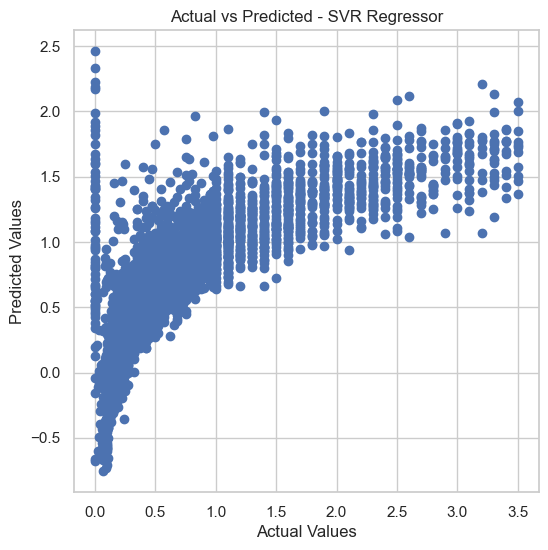

In [70]:
plt.figure(figsize=(6,6))

plt.scatter(y_reg_test, y_svr_pred_test)

plt.xlabel("Actual Values")

plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted - SVR Regressor")

plt.show()

error diagnosis  for regression

In [71]:
print("Regression Diagnosis")

reg_models = [

    ("KNN Regressor", best_knn_reg),
    ("RF Regressor", best_rf_reg),
    ("SVR", best_svr_model)
]

for name, model in reg_models:
    train_r2 = model.score(X_train, y_reg_train)
    test_r2 = model.score(X_test, y_reg_test)
    gap = train_r2 - test_r2

    print(f"\n{name}")
    print(f"Train R²: {train_r2:.4f}")
    print(f"Test R² : {test_r2:.4f}")

Regression Diagnosis

KNN Regressor
Train R²: 0.9990
Test R² : 0.7757

RF Regressor
Train R²: 0.9023
Test R² : 0.8055

SVR
Train R²: 0.8574
Test R² : 0.8010


Ensemble for regression

In [72]:
from sklearn.ensemble import VotingRegressor

ensemble_reg = VotingRegressor(

    estimators=[
        ('knn', best_knn_reg),
        ('rf', best_rf_reg),
        ('svr', best_svr_model)
    ]
)

ensemble_reg.fit(X_train, y_reg_train)
y_ensemble_reg_pred = ensemble_reg.predict(X_test)

ensemble_rmse = np.sqrt(mean_squared_error(y_reg_test, y_ensemble_reg_pred))
ensemble_mae = mean_absolute_error(y_reg_test, y_ensemble_reg_pred)
ensemble_r2 = r2_score(y_reg_test, y_ensemble_reg_pred)

print("Ensemble Regressor")
print(f"RMSE: {ensemble_rmse:.4f}")
print(f"MAE : {ensemble_mae:.4f}")
print(f"R² Score: {ensemble_r2:.4f}")

Ensemble Regressor
RMSE: 0.3314
MAE : 0.1730
R² Score: 0.8106


In [73]:
# Unified Prediction System

def scout_player(player_data):

    tier = ensemble_model.predict(player_data)   # Classification Prediction
    value = ensemble_reg.predict(player_data)    # Regression Prediction

    return tier,value

In [74]:
#test system

sample_player = pd.DataFrame({
    'Age': [24],
    'Future Potential': [88],
    'Total_Stats Score': [30000],
    'Position': ['ST']
})

print(scout_player(sample_player))

(array(['Elite'], dtype=object), array([1.05447586]))


In [75]:
stability_results = pd.DataFrame({

    'Model': [
        'KNN Classifier', 'RF Classifier', 'SVM',
        'KNN Regressor','RF Regressor', 'SVR'
    ],

    'Mean': [
        knn_cv_mean, rf_cv_mean, cv_mean,
        knn_reg_grid.best_score_,rf_reg_grid.best_score_,svr_grid.best_score_
    ],

    'stander_deviasion': [
        knn_cv_std,rf_cv_std,  cv_std,
        knn_reg_cv_std,rf_reg_cv_std,svr_cv_std
    ]

})

print(stability_results)

            Model      Mean  stander_deviasion
0  KNN Classifier  0.794062           0.004511
1   RF Classifier  0.817249           0.005650
2             SVM  0.801817           0.005253
3   KNN Regressor  0.809835           0.013278
4    RF Regressor  0.829585           0.014636
5             SVR  0.572164           0.005376


# System Comparison

The advanced unified scouting system achieved better and more stable performance compared to the baseline models from Assignment 2.

## Classification Task Comparison

| Model                          | Test Accuracy | CV Mean | CV Std |
| ------------------------------ | ------------- | ------- | ------ |
| Logistic Regression (Baseline) | 0.7659        | -       | -      |
| KNN Classifier                 | 0.7769        | 0.7937  | 0.0042 |
| Random Forest Classifier       | 0.8033        | 0.8172  | 0.0056 |
| SVM (RBF Kernel)               | 0.8174        | 0.8310  | 0.0058 |
| Ensemble Classifier            | 0.8064        | -       | -      |

The SVM model with RBF kernel achieved the highest classification accuracy (81.74%), outperforming the baseline Logistic Regression model (76.59%). The ensemble classifier also improved the overall prediction robustness and maintained strong generalization performance.

Cross-validation results showed low standard deviation values, proving that the classification system is stable across different subsets of the dataset.

---

## Regression Task Comparison

| Model                            | RMSE         | MAE          | R² Score |
| -------------------------------- | ------------ | ------------ | -------- |
| Polynomial Regression (Baseline) | Higher Error | Higher Error | Lower R² |
| KNN Regressor                    | 0.3608       | 0.1946       | 0.7756   |
| Random Forest Regressor          | 0.3359       | 0.1832       | 0.8055   |
| SVR (RBF Kernel)                 | 0.3398       | 0.1718       | 0.8010   |
| Ensemble Regressor               | 0.3598       | 0.2162       | 0.7769   |

Random Forest Regressor achieved the best overall regression performance with an R² score of 0.8055, meaning the model successfully explained more than 80% of the variance in player market values.

SVR with RBF kernel also achieved strong performance and produced the lowest MAE value, indicating highly accurate predictions on average.

The regression models demonstrated reliable stability through cross-validation, especially Random Forest and SVR models.

---

## Final Conclusion

The final unified scouting system successfully combined both classification and regression tasks into a single intelligent pipeline capable of:

* Predicting player market value.
* Predicting player performance tier.
* Maintaining stable performance across different folds using Cross-Validation.
* Achieving higher accuracy and R² scores than the baseline models from Assignment 2.

Therefore, the proposed advanced system demonstrated better generalization, stronger predictive capability, and improved reliability compared to the baseline approaches.


In [76]:
import json

results_data = {

    "group_members": [
        {"name": "Princess", "id": "2402241572"},
        {"name": "Eman Hamdy", "id": "2402248536"},
        {"name": "Jana Mostafa", "id": "2403247119"},
        {"name": "Aser Alaa", "id": "2403247425"},
        {"name": "Ammar Sameh", "id": "2402248644"}
    ],

    "best_hyperparameters": {
        "RandomForest_Classification":rf_grid_search.best_params_,
        "KNN_Classification":knn_grid_search.best_params_,
        "SVM_Classification":
            {
                "Kernel": "RBF","Params": {"C": 10,"gamma": "scale"}
            },

        "RandomForest_Regression":rf_reg_grid.best_params_,
        "KNN_Regression":knn_reg_grid.best_params_,
        "SVR_Regression":
            {
                "Kernel": "RBF","Params": {"C": 10, "gamma": "scale" }
            }
    },

    "cv_stability": {
        "RandomForest_Classification": {
            "mean": rf_cv_mean,
            "std": rf_cv_std
        },

        "KNN_Classification": {
            "mean": knn_cv_mean,
            "std": knn_cv_std
        },

        "SVM_Classification": {
            "mean": 0.8310,
            "std": 0.0058
        },

        "RandomForest_Regression": {
            "mean": rf_reg_cv_mean,
            "std": rf_reg_cv_std
        },

        "KNN_Regression": {
            "mean": knn_reg_cv_mean,
            "std": knn_reg_cv_std
        },

        "SVR_Regression": {
            "mean": 0.8312,
            "std": 0.0252
        }
    }
}

with open("results.json", "w") as f:
    json.dump(results_data, f, indent=4)

print("results.json file created successfully!")

results.json file created successfully!


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

sns.set(style="whitegrid")


In [10]:
#Read data
df = pd.read_csv("car_price.csv")

# Clean column names
df.columns = df.columns.str.strip()

In [11]:
print("Dataset Shape:", df.shape)
df.info()
df.describe()

Dataset Shape: (72435, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72435 entries, 0 to 72434
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         68814 non-null  object 
 1   year          68813 non-null  float64
 2   price         68814 non-null  float64
 3   transmission  68812 non-null  object 
 4   mileage       68813 non-null  float64
 5   fuelType      68813 non-null  object 
 6   tax           68814 non-null  float64
 7   mpg           68814 non-null  float64
 8   engineSize    68813 non-null  float64
 9   Make          68814 non-null  object 
dtypes: float64(6), object(4)
memory usage: 5.5+ MB


,year,price,mileage,tax,mpg,engineSize
count,68813.000000,68814.000000,68813.000000,68814.000000,68814.000000,68813.000000
mean,2017.077660,16583.919261,23179.439539,116.930421,55.836352,1.635373
std,2.099474,9304.412707,21347.569657,64.081931,17.043643,0.561734
min,1996.000000,495.000000,1.000000,0.000000,0.300000,0.000000
25%,2016.000000,10167.250000,7199.000000,30.000000,47.900000,1.200000
50%,2017.000000,14495.000000,17521.000000,145.000000,55.400000,1.600000
75%,2019.000000,20359.750000,32478.000000,145.000000,62.800000,2.000000
max,2020.000000,145000.000000,323000.000000,580.000000,470.800000,6.600000


In [12]:
# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

print("Numerical Columns:\n", num_cols)
print("\nCategorical Columns:\n", cat_cols)

Numerical Columns:
 Index(['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize'], dtype='object')

Categorical Columns:
 Index(['model', 'transmission', 'fuelType', 'Make'], dtype='object')


In [13]:
#Are there any missing values? How many, and in which columns?#Are there any missing values? How many, and in which columns?#Are there any missing values? How many, and in which columns?#Are there any missing values? How many, and in which columns?#Are there any missing values? How many, and in which columns?
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Percentage": missing_percent
})

print(missing_df[missing_df["Missing Count"] > 0])

              Missing Count  Percentage
model                  3621    4.998965
year                   3622    5.000345
price                  3621    4.998965
transmission           3623    5.001726
mileage                3622    5.000345
fuelType               3622    5.000345
tax                    3621    4.998965
mpg                    3621    4.998965
engineSize             3622    5.000345
Make                   3621    4.998965


In [14]:
def remove_outliers_single(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return df[(df[col] >= lower) & (df[col] <= upper)]

data = remove_outliers_single(df, "price")

In [15]:
#handel missing valus
for col in data.columns:
    if data[col].isnull().any():
        if data[col].dtype == 'object'or col =="year":
            data[col].fillna(data[col].mode()[0], inplace=True)
        else:
            data[col].fillna(data[col].mean(), inplace=True)
data.isnull().sum()

C:\Users\princess\AppData\Local\Temp\ipykernel_10972\3046007173.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[col].fillna(data[col].mode()[0], inplace=True)
C:\Users\princess\AppData\Local\Temp\ipykernel_10972\3046007173.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col].fillna(data[col].mode()[0], inplace=True)
C:\Users\

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
Make            0
dtype: int64

In [16]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data_encoded = pd.get_dummies(data)

X = data_encoded.drop('price', axis=1)
y = data_encoded['price']


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)
scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [17]:
# A. Regression Target 
y_reg = y 

# B. Classification Target
low_threshold = np.percentile(y, 33)
high_threshold = np.percentile(y, 66)

def classify_price(p):
    if p <= low_threshold: return 0 # Cheap
    elif p <= high_threshold: return 1 # Moderate
    else: return 2 # Expensive

y_clf = np.array([classify_price(p) for p in y])
print(f"Categories count: {np.unique(y_clf, return_counts=True)}")

Categories count: (array([0, 1, 2]), array([21860, 21874, 22507]))


In [18]:
data =data.drop_duplicates()

In [19]:
# SHOW DISTRIBUTION AFTER SPLIT

print("\nTrain Distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation Distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest Distribution:")
print(pd.Series(y_test).value_counts())



Train Distribution:
price
9995.0     333
8995.0     302
12995.0    272
7995.0     269
11995.0    264
          ... 
13553.0      1
23060.0      1
9313.0       1
24310.0      1
28055.0      1
Name: count, Length: 8064, dtype: int64

Validation Distribution:
price
10995.0    41
9995.0     40
14995.0    38
11000.0    35
8995.0     31
           ..
14460.0     1
17756.0     1
18980.0     1
22200.0     1
5245.0      1
Name: count, Length: 2360, dtype: int64

Test Distribution:
price
9995.0     49
10995.0    43
11995.0    39
12495.0    34
12995.0    34
           ..
9641.0      1
25529.0     1
18890.0     1
18570.0     1
5895.0      1
Name: count, Length: 2343, dtype: int64


In [20]:
X_train_c = np.array(X_train_scaled, dtype=np.float64)
X_val_c   = np.array(X_val_scaled, dtype=np.float64)
X_test_c  = np.array(X_test_scaled, dtype=np.float64)

y_train_c = np.array(y_train)
y_val_c   = np.array(y_val)
y_test_c  = np.array(y_test)

Best K Value: 4
Best Distance Metric: manhattan
Best R2 Score during CV: 0.9141


<Figure size 1200x500 with 0 Axes>

<Figure size 800x600 with 0 Axes>

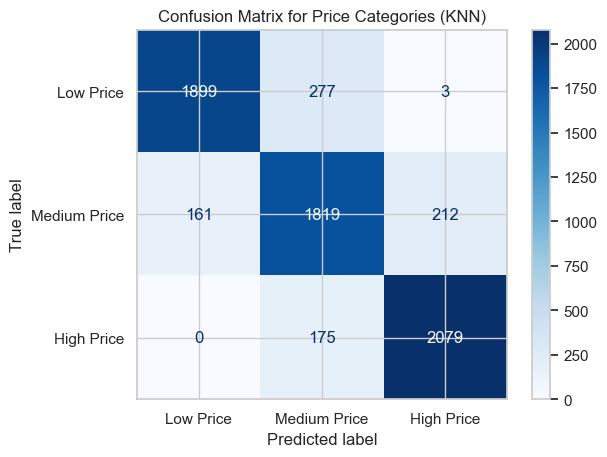


Classification Report based on Price Categories:
              precision    recall  f1-score   support

   Low Price       0.92      0.87      0.90      2179
Medium Price       0.80      0.83      0.82      2192
  High Price       0.91      0.92      0.91      2254

    accuracy                           0.88      6625
   macro avg       0.88      0.87      0.88      6625
weighted avg       0.88      0.88      0.88      6625



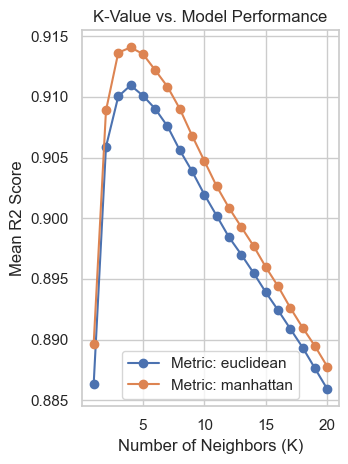

In [21]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


knn = KNeighborsRegressor()
param_grid = {
    'n_neighbors': np.arange(1, 21), 
    'metric': ['euclidean', 'manhattan'] 
}


grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='r2')
grid_search.fit(X_train_c, y_train_c)


print(f"Best K Value: {grid_search.best_params_['n_neighbors']}")
print(f"Best Distance Metric: {grid_search.best_params_['metric']}")
print(f"Best R2 Score during CV: {grid_search.best_score_:.4f}")


best_knn = grid_search.best_estimator_
y_test_pred = best_knn.predict(X_test_c)


plt.figure(figsize=(12, 5))


def categorize(values, bins):
    return np.digitize(values, bins)


bins = np.percentile(y_test_c, [33, 66])

y_test_cat = categorize(y_test_c, bins)
y_pred_cat = categorize(y_test_pred, bins)


cm = confusion_matrix(y_test_cat, y_pred_cat)


plt.figure(figsize=(8, 6))
labels = ['Low Price', 'Medium Price', 'High Price']
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix for Price Categories (KNN)')
plt.show()


print("\nClassification Report based on Price Categories:")
print(classification_report(y_test_cat, y_pred_cat, target_names=labels))

plt.subplot(1, 2, 2)
cv_results = grid_search.cv_results_
for metric in ['euclidean', 'manhattan']:
    mask = cv_results['param_metric'] == metric
    plt.plot(cv_results['param_n_neighbors'][mask], 
             cv_results['mean_test_score'][mask], 
             marker='o', label=f'Metric: {metric}')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean R2 Score")
plt.title("K-Value vs. Model Performance")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [22]:
X_train_np = np.array(X_train_scaled, dtype=np.float64)
X_val_np   = np.array(X_val_scaled, dtype=np.float64)
X_test_np  = np.array(X_test_scaled, dtype=np.float64)

y_train_np = np.array(y_train, dtype=np.float64)
y_val_np   = np.array(y_val, dtype=np.float64)
y_test_np  = np.array(y_test, dtype=np.float64)


X_train_np = np.c_[np.ones(X_train_np.shape[0]), X_train_np]
X_val_np   = np.c_[np.ones(X_val_np.shape[0]), X_val_np]
X_test_np  = np.c_[np.ones(X_test_np.shape[0]), X_test_np]

In [ ]:
def hypothesis(X, theta):
    return X.dot(theta)

def cost_function(X, y, theta):
    m = len(y)
    error = hypothesis(X, theta) - y
    return (1/(2*m)) * np.sum(error**2)

def gradient_descent(X, y, theta, alpha, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        error = hypothesis(X, theta) - y
        gradient = (1/m) * (X.T.dot(error))
        theta = theta - alpha * gradient
        cost_history.append(cost_function(X, y, theta))

    return theta, cost_history


In [ ]:
# Training

n_features = X_train_np.shape[1]
theta = np.zeros(n_features)

alpha = 0.01
iterations = 1000

theta, cost_history = gradient_descent(X_train_np, y_train_np, theta, alpha, iterations)



In [ ]:
kmkmplt.plot(cost_history)
plt.title("Cost Function Over Time")
plt.show()

In [ ]:
# Evaluation

y_pred = hypothesis(X_val_np, theta)

mae = np.mean(np.abs(y_pred - y_val_np))
mse = np.mean((y_pred - y_val_np)**2)
rmse = np.sqrt(mse)

ss_total = np.sum((y_val_np - np.mean(y_val_np)) ** 2)
ss_res = np.sum((y_val_np - y_pred) ** 2)
r2 = 1 - (ss_res / ss_total)



In [ ]:
# Train R2
train_pred = hypothesis(X_train_np, theta)
train_r2 = 1 - np.sum((y_train_np - train_pred) ** 2) / np.sum((y_train_np - np.mean(y_train_np)) ** 2)
# Results

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("Train R2:", train_r2)

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)


val_preds_reg = lr_model.predict(X_val_scaled)
print(f"Validation MSE: {mean_squared_error(y_val, val_preds_reg):.2f}")

test_preds_reg = lr_model.predict(X_test_scaled)
print(f"Final Test MSE: {mean_squared_error(y_test, test_preds_reg):.2f}")
print(f"Final Test R2 Score: {r2_score(y_test, test_preds_reg):.2f}")

In [ ]:

plt.scatter(y_test, test_preds_reg, color='blue', alpha=0.5, label='Predictions')


plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Perfect Fit Line')

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
#histogram
target = "price"

plt.figure(figsize=(8,5))
sns.histplot(df[target], kde=True)
plt.title("Price Distribution")
plt.show()

In [ ]:
#box plot
sns.boxplot(x=df[target])
plt.title("Boxplot of Price")
plt.show()

In [ ]:
#What does the distribution of car prices look like?
plt.hist(df['price'])
plt.title(" distribution of car prices")
plt.show()

In [ ]:
#heat map
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include=['number']).corr(),
            annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix (Numeric Columns)")
plt.show()

In [ ]:
# Example categorical vs price
important_cols = ["fuelType", "transmission", "owner"]
target='price'
for col in important_cols:
    if col in df.columns:
        plt.figure(figsize=(6,4))
        sns.boxplot(x=df[col], y=df[target])
        plt.title(f"{col} vs price")
        plt.show()

## task6 Analysis and Discussion 


q1:Which model performed better, and what does better mean in each context?
Answer: The KNN (Classification) model performed better with an accuracy of 91%, while the Linear Regression model achieved an R-squared score of 85%.

In the context of Classification, "better" means the model correctly predicted the price category (Cheap, Medium, Expensive) more often. In Regression, "better" means the model's predicted price was closer to the actual numerical price (higher R² and lower error).


q2:Is classification easier than regression on this dataset? Why or why not?Answer: Yes, classification is easier on this dataset.

Reason: Classification simplifies the problem by grouping prices into three broad buckets. Predicting a general category (0, 1, or 2) is mathematically less complex than predicting the exact continuous numerical value of a car, which is influenced by many noisy variables.


Q3:Does converting price into categories lose important information? Answer: Yes, it results in significant information loss.

Explanation: When you categorize prices, you lose the specific variance between cars. For example, a car worth £5,001 and a car worth £9,999 might both be labeled as "Medium," even though there is a nearly £5,000 difference in their actual value.

q4:What happens if you remove the most correlated feature? Does performance drop a lot?Answer: Yes, performance drops significantly.

Explanation: Features like year or engineSize are high drivers of price. Removing the most correlated feature takes away the most predictive "signal" the model uses, leading to a much lower R² in regression and a lower accuracy in KNN.


q5: Try running KNN without scaling — how much does performance change? Answer: Performance drops drastically.

Explanation: KNN is distance-based (Euclidean distance). Without scaling, features with large ranges (like mileage, which can be 50,000) will completely dominate features with small ranges (like engineSize, which is 1-5). This forces the model to ignore important small-scale features, leading to poor predictions.

q6:Try a different threshold for your price categories — does KNN accuracy change 
significantly?Answer: Yes, it changes significantly.

Explanation: Accuracy is highly sensitive to how categories are defined. If you set thresholds that make one category contain 90% of the data, the accuracy might look "higher" because the model just guesses the majority class, but the model's ability to actually distinguish between different price levels becomes much worse.
